<a href="https://colab.research.google.com/github/Cyube3/Dec2024_mediapipe_gait/blob/main/EC523ProjectColab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==========================================
# RUN THIS ONCE TO PREPARE DATASET
# ==========================================
import os
from tqdm import tqdm
from PIL import Image
from datasets import load_dataset
from huggingface_hub import notebook_login
from google.colab import drive

# 1. Mount Drive and Login
drive.mount('/content/drive')
notebook_login() # Paste your HF token here when prompted

# 2. Create local directories on Colab's fast disk
base_dir = '/content/imagenet_subset'
train_dir = os.path.join(base_dir, 'train')
test_dir = os.path.join(base_dir, 'test')
os.makedirs(train_dir, exist_ok=True)
os.makedirs(test_dir, exist_ok=True)

# 3. Stream the dataset
print("Streaming training set...")
train_stream = load_dataset("ILSVRC/imagenet-1k", split="train", streaming=True)
train_iterator = iter(train_stream)

for i in tqdm(range(10000), desc="Saving Train Images"):
    sample = next(train_iterator)
    img = sample['image'].convert("RGB").resize((256, 256))
    img.save(os.path.join(train_dir, f'img_{i:05d}.jpg'))

print("Streaming testing set...")
test_stream = load_dataset("ILSVRC/imagenet-1k", split="validation", streaming=True)
test_iterator = iter(test_stream)

for i in tqdm(range(1000), desc="Saving Test Images"):
    sample = next(test_iterator)
    img = sample['image'].convert("RGB").resize((256, 256))
    img.save(os.path.join(test_dir, f'img_{i:04d}.jpg'))

# 4. Zip the folder and move it to Google Drive
print("Zipping dataset...")
!zip -rq /content/imagenet_subset.zip /content/imagenet_subset

print("Moving to Google Drive...")
!cp /content/imagenet_subset.zip /content/drive/MyDrive/

print("Done zipping file on the Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Streaming training set...


Resolving data files:   0%|          | 0/294 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/28 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/294 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/28 [00:00<?, ?it/s]

...

Resolving data files:   0%|          | 0/28 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/294 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/28 [00:00<?, ?it/s]

Saving Test Images: 100%|██████████| 1000/1000 [00:11<00:00, 84.61it/s]


Zipping dataset...
Moving to Google Drive...
Done zipping file on the Drive.


## Version 1.0: Baseline Attention-Enhanced U-Net
This initial implementation builds a fully custom conditional Generative Adversarial Network (cGAN) from scratch to perform image colorization.

**Core Architectural Components:**
* **Data Pipeline (LAB Color Space):** The model converts RGB images into the CIELAB color space. The `L` (lightness) channel is isolated as the 1-channel grayscale input, while the model is tasked with predicting the 2-channel `ab` (chromaticity) output. All tensors are normalized to a `[-1, 1]` range for neural network stability.
* **The Generator (Attention U-Net):** A custom-built Convolutional Encoder-Decoder.
  * The **Encoder** shrinks the image through 5 convolutional blocks to extract spatial features.
  * The **Decoder** upsamples the image, utilizing **Attention Gates** on the skip connections. Instead of blindly copying data from the encoder, these gates actively filter the features, allowing the network to focus on salient objects (like faces or skies) while suppressing irrelevant background noise.
* **The Discriminator (PatchGAN):** Instead of evaluating the entire image as a single "Real/Fake" output, the PatchGAN evaluates local $N \times N$ patches. This penalizes the generator for unrealistic local textures, enforcing crisp, high-frequency details.
* **Loss Function:** The network optimizes a combination of **L1 Reconstruction Loss** (to enforce pixel-level color accuracy) and **Adversarial Loss** (to trick the PatchGAN into seeing realistic color distributions).

In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import numpy as np
from skimage.color import rgb2lab, lab2rgb
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr
from tqdm import tqdm
import warnings

# Mount Drive
from google.colab import drive
drive.mount('/content/drive')

# Copy from Drive and unzip locally
!cp /content/drive/MyDrive/imagenet_subset.zip /content/
!unzip -q -o /content/imagenet_subset.zip -d /

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
class LocalColorizationDataset(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_dir = image_dir
        self.image_paths = [os.path.join(image_dir, f) for f in os.listdir(image_dir) if f.endswith('.jpg')]
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        img = Image.open(img_path).convert("RGB")

        if self.transform:
            img = self.transform(img)

        img = np.array(img)
        img_lab = rgb2lab(img).astype("float32")
        img_lab = transforms.ToTensor()(img_lab)

        L = img_lab[[0], ...] / 50.0 - 1.0
        ab = img_lab[[1, 2], ...] / 110.0

        return L, ab

# Setup DataLoaders
train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
])

train_dir = '/content/imagenet_subset/train'
test_dir = '/content/imagenet_subset/test'

train_loader = DataLoader(LocalColorizationDataset(train_dir, transform=train_transforms), batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(LocalColorizationDataset(test_dir), batch_size=8, shuffle=False)

print(f"Loaded {len(train_loader.dataset)} training images and {len(test_loader.dataset)} testing images.")

Loaded 10000 training images and 1000 testing images.


In [ ]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super(ConvBlock, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super(AttentionGate, self).__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class AttentionUNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=2):
        super(AttentionUNet, self).__init__()
        self.Maxpool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.Conv1 = ConvBlock(in_ch, 64)
        self.Conv2 = ConvBlock(64, 128)
        self.Conv3 = ConvBlock(128, 256)
        self.Conv4 = ConvBlock(256, 512)
        self.Conv5 = ConvBlock(512, 1024)

        self.Up5 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.Att5 = AttentionGate(F_g=512, F_l=512, F_int=256)
        self.Up_conv5 = ConvBlock(1024, 512)

        self.Up4 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.Att4 = AttentionGate(F_g=256, F_l=256, F_int=128)
        self.Up_conv4 = ConvBlock(512, 256)

        self.Up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.Att3 = AttentionGate(F_g=128, F_l=128, F_int=64)
        self.Up_conv3 = ConvBlock(256, 128)

        self.Up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.Att2 = AttentionGate(F_g=64, F_l=64, F_int=32)
        self.Up_conv2 = ConvBlock(128, 64)

        self.Conv_1x1 = nn.Conv2d(64, out_ch, kernel_size=1, stride=1, padding=0)
        self.tanh = nn.Tanh()

    def forward(self, x):
        e1 = self.Conv1(x)
        e2 = self.Conv2(self.Maxpool(e1))
        e3 = self.Conv3(self.Maxpool(e2))
        e4 = self.Conv4(self.Maxpool(e3))
        e5 = self.Conv5(self.Maxpool(e4))

        d5 = self.Up5(e5)
        x4 = self.Att5(g=d5, x=e4)
        d5 = torch.cat((x4, d5), dim=1)
        d5 = self.Up_conv5(d5)

        d4 = self.Up4(d5)
        x3 = self.Att4(g=d4, x=e3)
        d4 = torch.cat((x3, d4), dim=1)
        d4 = self.Up_conv4(d4)

        d3 = self.Up3(d4)
        x2 = self.Att3(g=d3, x=e2)
        d3 = torch.cat((x2, d3), dim=1)
        d3 = self.Up_conv3(d3)

        d2 = self.Up2(d3)
        x1 = self.Att2(g=d2, x=e1)
        d2 = torch.cat((x1, d2), dim=1)
        d2 = self.Up_conv2(d2)

        out = self.Conv_1x1(d2)
        return self.tanh(out)

class PatchGANDiscriminator(nn.Module):
    def __init__(self, in_ch=3):
        super(PatchGANDiscriminator, self).__init__()

        def discriminator_block(in_filters, out_filters, normalization=True):
            layers = [nn.Conv2d(in_filters, out_filters, 4, stride=2, padding=1)]
            if normalization:
                layers.append(nn.BatchNorm2d(out_filters))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            *discriminator_block(in_ch, 64, normalization=False),
            *discriminator_block(64, 128),
            *discriminator_block(128, 256),
            *discriminator_block(256, 512),
            nn.ZeroPad2d((1, 0, 1, 0)),
            nn.Conv2d(512, 1, 4, padding=1, bias=False)
        )

    def forward(self, L, ab):
        img_input = torch.cat((L, ab), dim=1)
        return self.model(img_input)

In [ ]:
def lab_to_rgb_tensor(L, ab):
    """Helper to un-normalize and convert tensors back to RGB."""
    L_unnorm = (L + 1.0) * 50.0
    ab_unnorm = ab * 110.0
    lab = torch.cat((L_unnorm, ab_unnorm), dim=1)

    lab_np = lab.detach().cpu().numpy().transpose(0, 2, 3, 1)
    rgb_images = []
    for i in range(lab_np.shape[0]):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            rgb_img = lab2rgb(lab_np[i])
        rgb_images.append(rgb_img)
    return np.array(rgb_images)

def train(generator, discriminator, train_loader, epochs=50, save_dir='/content/drive/MyDrive/Colorization_Models'):
    os.makedirs(save_dir, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    generator = generator.to(device)
    discriminator = discriminator.to(device)

    criterion_GAN = nn.BCEWithLogitsLoss()
    criterion_L1 = nn.L1Loss()
    lambda_L1 = 100.0

    opt_G = optim.Adam(generator.parameters(), lr=2e-4, betas=(0.5, 0.999))
    opt_D = optim.Adam(discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999))

    for epoch in range(epochs):
        loop = tqdm(train_loader, leave=True)

        for L, ab_real in loop:
            L, ab_real = L.to(device), ab_real.to(device)

            # Train Discriminator
            opt_D.zero_grad()
            pred_real = discriminator(L, ab_real)
            loss_real = criterion_GAN(pred_real, torch.ones_like(pred_real))

            ab_fake = generator(L)
            pred_fake = discriminator(L, ab_fake.detach())
            loss_fake = criterion_GAN(pred_fake, torch.zeros_like(pred_fake))

            loss_D = (loss_real + loss_fake) * 0.5
            loss_D.backward()
            opt_D.step()

            # Train Generator
            opt_G.zero_grad()
            pred_fake = discriminator(L, ab_fake)
            loss_G_GAN = criterion_GAN(pred_fake, torch.ones_like(pred_fake))
            loss_G_L1 = criterion_L1(ab_fake, ab_real)

            loss_G = loss_G_GAN + lambda_L1 * loss_G_L1
            loss_G.backward()
            opt_G.step()

            loop.set_description(f"Epoch [{epoch+1}/{epochs}]")
            loop.set_postfix(loss_D=loss_D.item(), loss_G=loss_G.item())

        # Checkpointing
        if (epoch + 1) % 10 == 0 or (epoch + 1) == epochs:
            checkpoint_path = os.path.join(save_dir, f'generator_epoch_{epoch+1}.pth')
            torch.save(generator.state_dict(), checkpoint_path)
            print(f"\nSaved checkpoint: {checkpoint_path}")

In [ ]:
# Initialize and run
generator = AttentionUNet(in_ch=1, out_ch=2)
discriminator = PatchGANDiscriminator(in_ch=3)

print("Starting training phase...")
# Note: The reference paper used 25 epochs[cite: 49]. Feel free to adjust.
train(generator, discriminator, train_loader, epochs=25)

Starting training phase...


Epoch [10/25]: 100%|██████████| 625/625 [12:29<00:00,  1.20s/it, loss_D=0.689, loss_G=10.4]



Saved checkpoint: /content/drive/MyDrive/Colorization_Models/generator_epoch_10.pth


Epoch [20/25]: 100%|██████████| 625/625 [12:30<00:00,  1.20s/it, loss_D=1.07, loss_G=12]



Saved checkpoint: /content/drive/MyDrive/Colorization_Models/generator_epoch_20.pth


Epoch [25/25]: 100%|██████████| 625/625 [12:31<00:00,  1.20s/it, loss_D=0.337, loss_G=10.8]



Saved checkpoint: /content/drive/MyDrive/Colorization_Models/generator_epoch_25.pth


Starting evaluation on test set...


  0%|          | 0/125 [00:00<?, ?it/s]

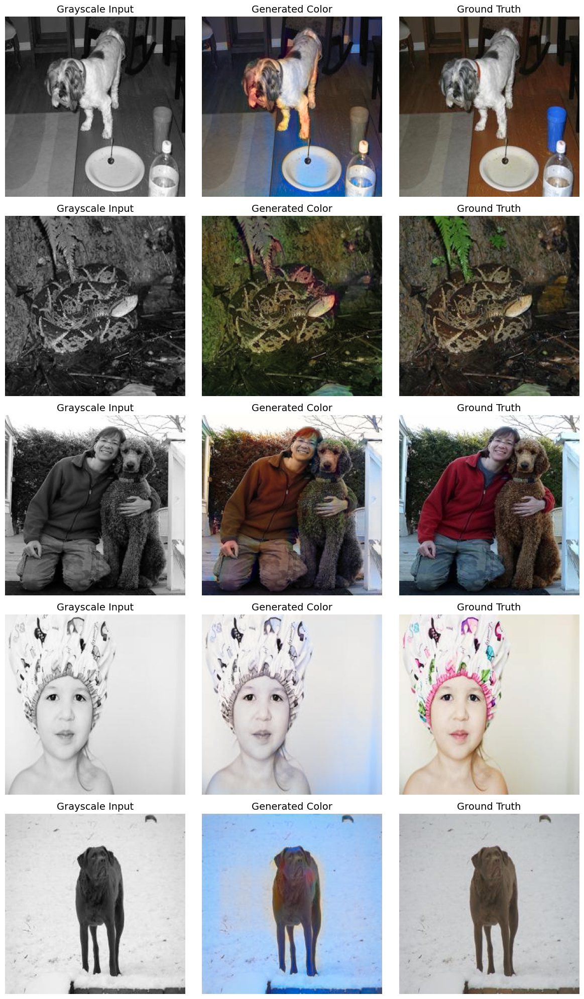

100%|██████████| 125/125 [01:01<00:00,  2.03it/s]


Final Test Results:
Average SSIM: 0.8965
Average PSNR: 20.8472


(np.float32(0.8964687), np.float64(20.847219661369508))

In [ ]:
import matplotlib.pyplot as plt

def evaluate_model(generator, test_loader, num_visualize=5):
    """
    Evaluates the model and visualizes a specified number of samples.
    num_visualize: Number of images to plot from the first batch.
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    generator = generator.to(device)
    generator.eval()

    total_ssim = 0.0
    total_psnr = 0.0
    num_batches = 0

    # Flag to ensure we only plot the first batch
    visualized = False

    print("Starting evaluation on test set...")
    with torch.no_grad():
        for L, ab_real in tqdm(test_loader):
            L = L.to(device)
            ab_fake = generator(L)

            # Convert tensors back to RGB numpy arrays for metric calculation
            rgb_fake = lab_to_rgb_tensor(L, ab_fake)
            rgb_real = lab_to_rgb_tensor(L.cpu(), ab_real)

            # ==========================================
            # VISUALIZATION BLOCK
            # ==========================================
            if not visualized:
                # Determine how many images to plot (bound by batch size)
                n_plot = min(num_visualize, L.shape[0])
                fig, axes = plt.subplots(n_plot, 3, figsize=(12, 4 * n_plot))

                # Handle edge case where n_plot == 1 (axes is 1D instead of 2D)
                if n_plot == 1:
                    axes = [axes]

                for i in range(n_plot):
                    # L channel is normalized [-1, 1]. Un-normalize to [0, 1] for matplotlib grayscale
                    gray_img = (L[i, 0].cpu().numpy() + 1.0) / 2.0

                    # Column 1: Grayscale Input
                    axes[i][0].imshow(gray_img, cmap='gray')
                    axes[i][0].set_title("Grayscale Input", fontsize=14)
                    axes[i][0].axis('off')

                    # Column 2: Generated Output
                    axes[i][1].imshow(rgb_fake[i])
                    axes[i][1].set_title("Generated Color", fontsize=14)
                    axes[i][1].axis('off')

                    # Column 3: Ground Truth
                    axes[i][2].imshow(rgb_real[i])
                    axes[i][2].set_title("Ground Truth", fontsize=14)
                    axes[i][2].axis('off')

                plt.tight_layout()
                plt.show()
                visualized = True # Prevent plotting subsequent batches
            # ==========================================

            # Calculate metrics for the batch
            batch_size = rgb_real.shape[0]
            for i in range(batch_size):
                current_ssim = ssim(rgb_real[i], rgb_fake[i], channel_axis=-1, data_range=1.0)
                current_psnr = psnr(rgb_real[i], rgb_fake[i], data_range=1.0)

                total_ssim += current_ssim
                total_psnr += current_psnr

            num_batches += batch_size

    avg_ssim = total_ssim / num_batches
    avg_psnr = total_psnr / num_batches

    print(f"\nFinal Test Results:")
    print(f"Average SSIM: {avg_ssim:.4f}")
    print(f"Average PSNR: {avg_psnr:.4f}")

    return avg_ssim, avg_psnr

# Run Evaluation and plot 5 sample outputs
evaluate_model(generator, test_loader, num_visualize=5)

## Version 1.1: Upgraded Transfer Learning Model
This upgraded implementation modifies the baseline model to achieve research-grade accuracy by integrating transfer learning, perceptual loss, and dynamic optimization. This directly addresses the limitations of training a complex generative encoder from scratch over a short epoch cycle.

**Key Upgrades & Improvements:**
1. **Pre-Trained ResNet34 Backbone:** The custom from-scratch encoder is completely replaced by a pre-trained `ResNet34` model. Because ResNet already possesses a deep semantic understanding of ImageNet objects, the model no longer wastes epochs learning basic edge detection. The Attention Gates in the decoder now filter highly sophisticated, pre-trained 2D spatial feature maps.
2. **Decoder Resolution Alignment:** ResNet34 applies an initial stride of 2, instantly shrinking the image to 128x128. An additional final upsampling block (`Up1`) and skip connection were engineered into the custom decoder to safely restore the image to the required 256x256 resolution without losing fidelity.
3. **VGG16 Perceptual Loss:** Standard L1 loss calculates pixel-by-pixel mathematical differences, which often leads to models "playing it safe" by generating muddy or blurry colors. We introduce a frozen `VGG16` network as a perceptual judge. By comparing the high-level feature maps of the generated image against the ground truth, the network is forced to produce sharper, perceptually realistic textures.
4. **Kaiming (He) Weight Initialization:** To prevent "gradient shock," the custom decoder layers are explicitly initialized using the Kaiming Normal method. This ensures that the randomly initialized, "dumb" decoder does not instantly corrupt the delicate, pre-trained weights of the ResNet34 backbone during the first few epochs of backpropagation.
5. **Dynamic Learning Rate Schedulers:** The static learning rate is replaced with a `ReduceLROnPlateau` scheduler. If the generator's loss stagnates for 3 consecutive epochs, the scheduler automatically halves the learning rate. This prevents erratic loss oscillations in the final stages of training, allowing the optimizer to make microscopic weight adjustments to maximize final SSIM and PSNR scores.

In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.models as models
from PIL import Image
import numpy as np
from skimage.color import rgb2lab, lab2rgb
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr
from tqdm import tqdm
import warnings

# Mount Drive
from google.colab import drive
drive.mount('/content/drive')

# The 5-Second Transfer: Copy from Drive and unzip locally
!cp /content/drive/MyDrive/imagenet_subset.zip /content/
!unzip -q -o /content/imagenet_subset.zip -d /

Mounted at /content/drive


In [ ]:
class LocalColorizationDataset(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_dir = image_dir
        self.image_paths = [os.path.join(image_dir, f) for f in os.listdir(image_dir) if f.endswith('.jpg')]
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        img = Image.open(img_path).convert("RGB")

        if self.transform:
            img = self.transform(img)

        img = np.array(img)
        img_lab = rgb2lab(img).astype("float32")
        img_lab = transforms.ToTensor()(img_lab)

        L = img_lab[[0], ...] / 50.0 - 1.0
        ab = img_lab[[1, 2], ...] / 110.0

        return L, ab

# Setup DataLoaders
train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
])

train_dir = '/content/imagenet_subset/train'
test_dir = '/content/imagenet_subset/test'

train_loader = DataLoader(LocalColorizationDataset(train_dir, transform=train_transforms), batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(LocalColorizationDataset(test_dir), batch_size=8, shuffle=False)

print(f"Loaded {len(train_loader.dataset)} training images and {len(test_loader.dataset)} testing images.")

Loaded 10000 training images and 1000 testing images.


In [ ]:
class VGG16FeatureExtractor(nn.Module):
    def __init__(self):
        super(VGG16FeatureExtractor, self).__init__()
        vgg16 = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1).features
        self.features = nn.Sequential(*list(vgg16.children())[:16]).eval()
        for param in self.parameters():
            param.requires_grad = False

    def forward(self, x):
        return self.features(x)

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super(ConvBlock, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super(AttentionGate, self).__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, kernel_size=1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, kernel_size=1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, kernel_size=1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class AttentionUNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=2):
        super(AttentionUNet, self).__init__()

        resnet = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1)

        # Sliced Encoder (Image goes 256 -> 128 -> 64 -> 32 -> 16 -> 8)
        self.enc1 = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu)
        self.enc2 = nn.Sequential(resnet.maxpool, resnet.layer1)
        self.enc3 = resnet.layer2
        self.enc4 = resnet.layer3
        self.enc5 = resnet.layer4

        # Decoder
        self.Up5 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.Att5 = AttentionGate(F_g=256, F_l=256, F_int=128)
        self.Up_conv5 = ConvBlock(512, 256)

        self.Up4 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.Att4 = AttentionGate(F_g=128, F_l=128, F_int=64)
        self.Up_conv4 = ConvBlock(256, 128)

        self.Up3 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.Att3 = AttentionGate(F_g=64, F_l=64, F_int=32)
        self.Up_conv3 = ConvBlock(128, 64)

        self.Up2 = nn.ConvTranspose2d(64, 64, kernel_size=2, stride=2)
        self.Att2 = AttentionGate(F_g=64, F_l=64, F_int=32)
        self.Up_conv2 = ConvBlock(128, 64)

        # --- NEW: Final Upsample Layer ---
        # Pushes the 128x128 output back to 256x256 to match the input.
        self.Up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        # 32 channels + 3 original input channels = 35 channels
        self.Up_conv1 = ConvBlock(35, 32)

        self.Conv_1x1 = nn.Conv2d(32, out_ch, kernel_size=1, stride=1, padding=0)
        self.tanh = nn.Tanh()

    def forward(self, x):
        x_repeated = x.repeat(1, 3, 1, 1)

        e1 = self.enc1(x_repeated)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        e5 = self.enc5(e4)

        d5 = self.Up5(e5)
        x4 = self.Att5(g=d5, x=e4)
        d5 = torch.cat((x4, d5), dim=1)
        d5 = self.Up_conv5(d5)

        d4 = self.Up4(d5)
        x3 = self.Att4(g=d4, x=e3)
        d4 = torch.cat((x3, d4), dim=1)
        d4 = self.Up_conv4(d4)

        d3 = self.Up3(d4)
        x2 = self.Att3(g=d3, x=e2)
        d3 = torch.cat((x2, d3), dim=1)
        d3 = self.Up_conv3(d3)

        d2 = self.Up2(d3)
        x1 = self.Att2(g=d2, x=e1)
        d2 = torch.cat((x1, d2), dim=1)
        d2 = self.Up_conv2(d2)

        d1 = self.Up1(d2)
        d1 = torch.cat((x_repeated, d1), dim=1)
        d1 = self.Up_conv1(d1)

        out = self.Conv_1x1(d1)
        return self.tanh(out)

class PatchGANDiscriminator(nn.Module):
    def __init__(self, in_ch=3):
        super(PatchGANDiscriminator, self).__init__()
        def discriminator_block(in_filters, out_filters, normalization=True):
            layers = [nn.Conv2d(in_filters, out_filters, 4, stride=2, padding=1)]
            if normalization:
                layers.append(nn.BatchNorm2d(out_filters))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers
        self.model = nn.Sequential(
            *discriminator_block(in_ch, 64, normalization=False),
            *discriminator_block(64, 128),
            *discriminator_block(128, 256),
            *discriminator_block(256, 512),
            nn.ZeroPad2d((1, 0, 1, 0)),
            nn.Conv2d(512, 1, 4, padding=1, bias=False)
        )
    def forward(self, L, ab):
        img_input = torch.cat((L, ab), dim=1)
        return self.model(img_input)

In [ ]:
def lab_to_rgb_tensor(L, ab):
    L_unnorm = (L + 1.0) * 50.0
    ab_unnorm = ab * 110.0
    lab = torch.cat((L_unnorm, ab_unnorm), dim=1)

    lab_np = lab.detach().cpu().numpy().transpose(0, 2, 3, 1)
    rgb_images = []
    for i in range(lab_np.shape[0]):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            rgb_img = lab2rgb(lab_np[i])
        rgb_images.append(rgb_img)
    return np.array(rgb_images)

def init_weights(m):
    """Applies Kaiming Normal initialization strictly to standard PyTorch layers."""
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.kaiming_normal_(m.weight.data, a=0, mode='fan_in')
        if m.bias is not None:
            nn.init.constant_(m.bias.data, 0.0)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0.0)

def train(generator, discriminator, vgg_model, train_loader, epochs=25, save_dir='/content/drive/MyDrive/Colorization_Models'):
    import re # Make sure regex is available for auto-discovery
    os.makedirs(save_dir, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    generator = generator.to(device)
    discriminator = discriminator.to(device)
    vgg_model = vgg_model.to(device)

    criterion_GAN = nn.BCEWithLogitsLoss()
    criterion_L1 = nn.L1Loss()
    criterion_VGG = nn.MSELoss()

    lambda_L1 = 100.0
    lambda_VGG = 10.0

    opt_G = optim.Adam(generator.parameters(), lr=2e-4, betas=(0.5, 0.999))
    opt_D = optim.Adam(discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999))

    scheduler_G = optim.lr_scheduler.ReduceLROnPlateau(opt_G, mode='min', factor=0.5, patience=3)
    scheduler_D = optim.lr_scheduler.ReduceLROnPlateau(opt_D, mode='min', factor=0.5, patience=3)

    start_epoch = 0

    # Scan directory for the new dictionary-based full checkpoints
    checkpoint_files = [f for f in os.listdir(save_dir) if f.startswith('full_checkpoint_epoch_') and f.endswith('.pth')]

    if checkpoint_files:
        # Sort and find the file with the highest epoch number
        latest_file = max(checkpoint_files, key=lambda f: int(re.search(r'epoch_(\d+)', f).group(1)))
        latest_checkpoint_path = os.path.join(save_dir, latest_file)

        print(f"Found latest full checkpoint: {latest_checkpoint_path}")
        checkpoint = torch.load(latest_checkpoint_path, map_location=device)

        generator.load_state_dict(checkpoint['generator_state_dict'])
        discriminator.load_state_dict(checkpoint['discriminator_state_dict'])
        opt_G.load_state_dict(checkpoint['optimizer_G_state_dict'])
        opt_D.load_state_dict(checkpoint['optimizer_D_state_dict'])
        scheduler_G.load_state_dict(checkpoint['scheduler_G_state_dict'])
        scheduler_D.load_state_dict(checkpoint['scheduler_D_state_dict'])
        start_epoch = checkpoint['epoch']

        print(f"Successfully loaded full checkpoint. Resuming training from Epoch {start_epoch+1}...")
    else:
        print("No full checkpoint found. Starting training from scratch...")

    # The loop dynamically starts from start_epoch
    for epoch in range(start_epoch, epochs):
        loop = tqdm(train_loader, leave=True)
        epoch_loss_G = 0
        epoch_loss_D = 0

        for L, ab_real in loop:
            L, ab_real = L.to(device), ab_real.to(device)

            # Train Discriminator
            opt_D.zero_grad()
            pred_real = discriminator(L, ab_real)
            loss_real = criterion_GAN(pred_real, torch.ones_like(pred_real))

            ab_fake = generator(L)
            pred_fake = discriminator(L, ab_fake.detach())
            loss_fake = criterion_GAN(pred_fake, torch.zeros_like(pred_fake))

            loss_D = (loss_real + loss_fake) * 0.5
            loss_D.backward()
            opt_D.step()

            # Train Generator
            opt_G.zero_grad()
            pred_fake = discriminator(L, ab_fake)
            loss_G_GAN = criterion_GAN(pred_fake, torch.ones_like(pred_fake))
            loss_G_L1 = criterion_L1(ab_fake, ab_real)

            # VGG Perceptual Loss
            real_images_cat = torch.cat((L, ab_real), dim=1)
            fake_images_cat = torch.cat((L, ab_fake), dim=1)
            real_features = vgg_model(real_images_cat)
            fake_features = vgg_model(fake_images_cat)
            loss_G_VGG = criterion_VGG(fake_features, real_features)

            loss_G = loss_G_GAN + (lambda_L1 * loss_G_L1) + (lambda_VGG * loss_G_VGG)
            loss_G.backward()
            opt_G.step()

            # Logging
            epoch_loss_G += loss_G.item()
            epoch_loss_D += loss_D.item()
            loop.set_description(f"Epoch [{epoch+1}/{epochs}]")
            loop.set_postfix(loss_D=loss_D.item(), loss_G=loss_G.item())

        avg_loss_G = epoch_loss_G / len(train_loader)
        avg_loss_D = epoch_loss_D / len(train_loader)
        scheduler_G.step(avg_loss_G)
        scheduler_D.step(avg_loss_D)

        # Checkpoint
        if (epoch + 1) % 5 == 0 or (epoch + 1) == epochs:
            checkpoint_path = os.path.join(save_dir, f'full_checkpoint_epoch_{epoch+1}.pth')
            # Save a complete dictionary of the network's current status
            checkpoint = {
                'epoch': epoch + 1,
                'generator_state_dict': generator.state_dict(),
                'discriminator_state_dict': discriminator.state_dict(),
                'optimizer_G_state_dict': opt_G.state_dict(),
                'optimizer_D_state_dict': opt_D.state_dict(),
                'scheduler_G_state_dict': scheduler_G.state_dict(),
                'scheduler_D_state_dict': scheduler_D.state_dict()
            }
            torch.save(checkpoint, checkpoint_path)
            print(f"\nSaved full checkpoint: {checkpoint_path}")

In [ ]:
# Initialize models
vgg_feature_extractor = VGG16FeatureExtractor()
generator = AttentionUNet(in_ch=1, out_ch=2)
discriminator = PatchGANDiscriminator(in_ch=3)

# Apply Kaiming Weight Initialization strictly to custom layers
discriminator.apply(init_weights)
generator.Up5.apply(init_weights)
generator.Att5.apply(init_weights)
generator.Up_conv5.apply(init_weights)
generator.Up4.apply(init_weights)
generator.Att4.apply(init_weights)
generator.Up_conv4.apply(init_weights)
generator.Up3.apply(init_weights)
generator.Att3.apply(init_weights)
generator.Up_conv3.apply(init_weights)
generator.Up2.apply(init_weights)
generator.Att2.apply(init_weights)
generator.Up_conv2.apply(init_weights)
generator.Up1.apply(init_weights)
generator.Up_conv1.apply(init_weights)
generator.Conv_1x1.apply(init_weights)

print("\n--- Starting Training Phase ---")
train(generator, discriminator, vgg_feature_extractor, train_loader, epochs=25)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 140MB/s]


Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 183MB/s]



--- Starting Training Phase ---
Found latest full checkpoint: /content/drive/MyDrive/Colorization_Models/full_checkpoint_epoch_10.pth
Successfully loaded full checkpoint. Resuming training from Epoch 11...


...


Saved full checkpoint: /content/drive/MyDrive/Colorization_Models/full_checkpoint_epoch_15.pth


Epoch [20/25]: 100%|██████████| 625/625 [07:39<00:00,  1.36it/s, loss_D=0.4, loss_G=14.7]



Saved full checkpoint: /content/drive/MyDrive/Colorization_Models/full_checkpoint_epoch_20.pth


Epoch [25/25]: 100%|██████████| 625/625 [07:41<00:00,  1.35it/s, loss_D=0.459, loss_G=12.3]



Saved full checkpoint: /content/drive/MyDrive/Colorization_Models/full_checkpoint_epoch_25.pth


Starting evaluation on test set...


  0%|          | 0/125 [00:00<?, ?it/s]

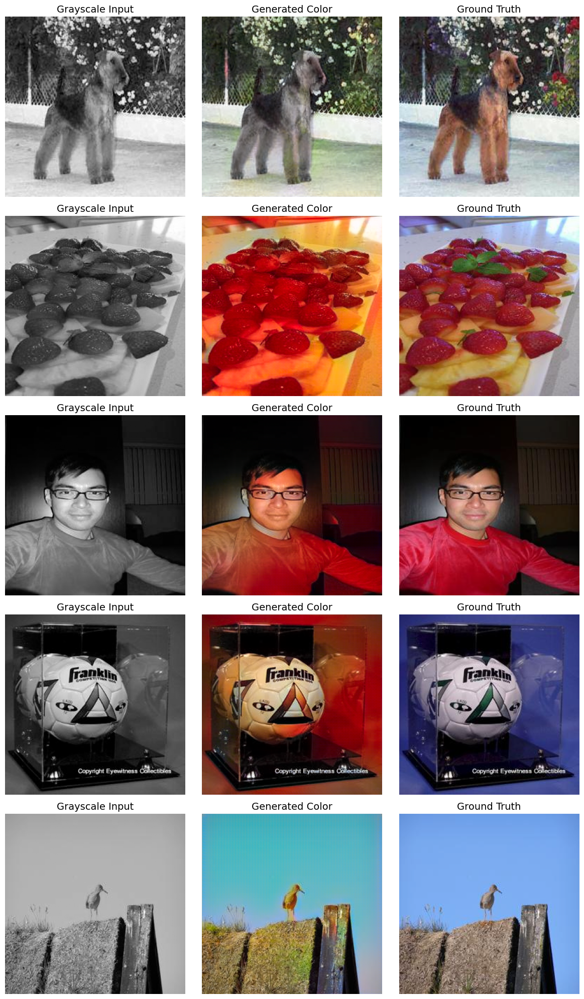

100%|██████████| 125/125 [00:53<00:00,  2.34it/s]


Final Test Results:
Average SSIM: 0.9027
Average PSNR: 22.2527


(np.float32(0.9026645), np.float64(22.252696433220724))

In [ ]:
import matplotlib.pyplot as plt

def evaluate_model(generator, test_loader, num_visualize=5):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    generator = generator.to(device)
    generator.eval()

    total_ssim = 0.0
    total_psnr = 0.0
    num_batches = 0
    visualized = False

    print("Starting evaluation on test set...")
    with torch.no_grad():
        for L, ab_real in tqdm(test_loader):
            L = L.to(device)
            ab_fake = generator(L)

            rgb_fake = lab_to_rgb_tensor(L, ab_fake)
            rgb_real = lab_to_rgb_tensor(L.cpu(), ab_real)

            # --- Visualizing Output ---
            if not visualized:
                n_plot = min(num_visualize, L.shape[0])
                fig, axes = plt.subplots(n_plot, 3, figsize=(12, 4 * n_plot))
                if n_plot == 1: axes = [axes]

                for i in range(n_plot):
                    gray_img = (L[i, 0].cpu().numpy() + 1.0) / 2.0
                    axes[i][0].imshow(gray_img, cmap='gray')
                    axes[i][0].set_title("Grayscale Input", fontsize=14)
                    axes[i][0].axis('off')

                    axes[i][1].imshow(rgb_fake[i])
                    axes[i][1].set_title("Generated Color", fontsize=14)
                    axes[i][1].axis('off')

                    axes[i][2].imshow(rgb_real[i])
                    axes[i][2].set_title("Ground Truth", fontsize=14)
                    axes[i][2].axis('off')

                plt.tight_layout()
                plt.show()
                visualized = True
            # --------------------------

            batch_size = rgb_real.shape[0]
            for i in range(batch_size):
                current_ssim = ssim(rgb_real[i], rgb_fake[i], channel_axis=-1, data_range=1.0)
                current_psnr = psnr(rgb_real[i], rgb_fake[i], data_range=1.0)

                total_ssim += current_ssim
                total_psnr += current_psnr

            num_batches += batch_size

    avg_ssim = total_ssim / num_batches
    avg_psnr = total_psnr / num_batches

    print(f"\nFinal Test Results:")
    print(f"Average SSIM: {avg_ssim:.4f}")
    print(f"Average PSNR: {avg_psnr:.4f}")

    return avg_ssim, avg_psnr

# Run Evaluation and plot the first 5 images
evaluate_model(generator, test_loader, num_visualize=5)

## Version 1.2: The "Global Context" & Stability Upgrade
This iteration pushes the architecture into true State-of-the-Art (SOTA) territory. Having solved the "muddy color" problem with VGG16 Perceptual Loss in the previous version, Version 1.2 targets the model's global spatial awareness and adversarial stability to push the SSIM score past the 0.91 threshold.

**Key Upgrades & Improvements:**
1. **ResNet50 Deep Backbone:** The encoder is upgraded from ResNet34 to `ResNet50`. The bottleneck layers now extract a massive 2048 feature channels (up from 512), providing the decoder with a vastly richer, more complex semantic vocabulary to translate into accurate colors.
2. **Self-Attention Bottleneck (SAGAN):** Standard convolutions only look at small, localized pixel patches. A custom `SelfAttention` block is inserted at the deepest part of the network to calculate a "relationship matrix" across the entire image. This guarantees global color consistency (e.g., ensuring a dog's tail matches its body color perfectly, regardless of pixel distance).
3. **Spectral Normalization (SN-GAN):** Because the generator is now significantly more powerful, the discriminator is prone to instability or being overpowered. We wrap the discriminator's convolutional layers in PyTorch's `spectral_norm`. This mathematically enforces a gradient "speed limit" (Lipschitz constraint), preventing GAN mode collapse and ensuring smooth, stable training.
4. **Huber Loss (Smooth L1):** Standard `L1Loss` creates harsh linear penalties that can sometimes cause minor pixelated artifacts in smooth, uniform areas (like open skies or blank walls). By swapping to `SmoothL1Loss`, the model applies L1 penalties to large color errors but smoothly transitions to L2 (squared) penalties for tiny details, polishing the final textures.
5. **Segmented Checkpoint Directory:** Because the network's tensor shapes have drastically changed to accommodate the new 2048-channel depth, the automated checkpoint system now saves to an isolated directory to ensure seamless auto-resuming without corrupting previous baseline weights.

In [ ]:
w# ==========================================
# 1. SETUP AND FAST DATA EXTRACTION
# ==========================================
import os
import re
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.utils.spectral_norm as spectral_norm
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.models as models
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from skimage.color import rgb2lab, lab2rgb
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr
from tqdm import tqdm
import warnings

# Mount Drive
from google.colab import drive
drive.mount('/content/drive')

# Copy and unzip data
!cp /content/drive/MyDrive/imagenet_subset.zip /content/
!unzip -q -o /content/imagenet_subset.zip -d /

Mounted at /content/drive


In [ ]:
# ==========================================
# 2. DATASET AND DATALOADERS
# ==========================================
class LocalColorizationDataset(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_dir = image_dir
        self.image_paths = [os.path.join(image_dir, f) for f in os.listdir(image_dir) if f.endswith('.jpg')]
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        img = Image.open(img_path).convert("RGB")

        if self.transform:
            img = self.transform(img)

        img = np.array(img)
        img_lab = rgb2lab(img).astype("float32")
        img_lab = transforms.ToTensor()(img_lab)

        L = img_lab[[0], ...] / 50.0 - 1.0
        ab = img_lab[[1, 2], ...] / 110.0

        return L, ab

train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
])

train_dir = '/content/imagenet_subset/train'
test_dir = '/content/imagenet_subset/test'

train_loader = DataLoader(LocalColorizationDataset(train_dir, transform=train_transforms), batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(LocalColorizationDataset(test_dir), batch_size=8, shuffle=False)

print(f"Loaded {len(train_loader.dataset)} training images and {len(test_loader.dataset)} testing images.")

Loaded 10000 training images and 1000 testing images.


In [ ]:
# ==========================================
# 3. VERSION 1.2 MODEL ARCHITECTURE
# ==========================================
class VGG16FeatureExtractor(nn.Module):
    def __init__(self):
        super(VGG16FeatureExtractor, self).__init__()
        vgg16 = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1).features
        self.features = nn.Sequential(*list(vgg16.children())[:16]).eval()
        for param in self.parameters():
            param.requires_grad = False

    def forward(self, x):
        return self.features(x)

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super(ConvBlock, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super(AttentionGate, self).__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, kernel_size=1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, kernel_size=1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, kernel_size=1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class SelfAttention(nn.Module):
    def __init__(self, in_channels):
        super(SelfAttention, self).__init__()
        self.query = nn.Conv2d(in_channels, in_channels // 8, 1)
        self.key = nn.Conv2d(in_channels, in_channels // 8, 1)
        self.value = nn.Conv2d(in_channels, in_channels, 1)
        self.gamma = nn.Parameter(torch.zeros(1))
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        batch_size, C, width, height = x.size()
        proj_query = self.query(x).view(batch_size, -1, width * height).permute(0, 2, 1)
        proj_key = self.key(x).view(batch_size, -1, width * height)
        energy = torch.bmm(proj_query, proj_key)
        attention = self.softmax(energy)
        proj_value = self.value(x).view(batch_size, -1, width * height)

        out = torch.bmm(proj_value, attention.permute(0, 2, 1))
        out = out.view(batch_size, C, width, height)
        out = self.gamma * out + x
        return out

class AttentionUNetV2(nn.Module):
    def __init__(self, in_ch=1, out_ch=2):
        super(AttentionUNetV2, self).__init__()

        # ResNet50 Backbone
        resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)

        # Sliced Encoder (Image goes 256 -> 128 -> 64 -> 32 -> 16 -> 8)
        self.enc1 = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu)     # Output: 64
        self.enc2 = nn.Sequential(resnet.maxpool, resnet.layer1)             # Output: 256
        self.enc3 = resnet.layer2                                            # Output: 512
        self.enc4 = resnet.layer3                                            # Output: 1024
        self.enc5 = resnet.layer4                                            # Output: 2048

        # Global Context Self-Attention at the Bottleneck
        self.bottleneck_attn = SelfAttention(2048)

        # Decoder (Adjusted for ResNet50 channel depths)
        self.Up5 = nn.ConvTranspose2d(2048, 1024, kernel_size=2, stride=2)
        self.Att5 = AttentionGate(F_g=1024, F_l=1024, F_int=512)
        self.Up_conv5 = ConvBlock(2048, 1024)

        self.Up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.Att4 = AttentionGate(F_g=512, F_l=512, F_int=256)
        self.Up_conv4 = ConvBlock(1024, 512)

        self.Up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.Att3 = AttentionGate(F_g=256, F_l=256, F_int=128)
        self.Up_conv3 = ConvBlock(512, 256)

        self.Up2 = nn.ConvTranspose2d(256, 64, kernel_size=2, stride=2)
        self.Att2 = AttentionGate(F_g=64, F_l=64, F_int=32)
        self.Up_conv2 = ConvBlock(128, 64)

        # Final Upsample Layer
        self.Up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.Up_conv1 = ConvBlock(35, 32)

        self.Conv_1x1 = nn.Conv2d(32, out_ch, kernel_size=1, stride=1, padding=0)
        self.tanh = nn.Tanh()

    def forward(self, x):
        x_repeated = x.repeat(1, 3, 1, 1)

        e1 = self.enc1(x_repeated)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        e5 = self.enc5(e4)

        # Apply Self-Attention to the deepest features
        e5 = self.bottleneck_attn(e5)

        d5 = self.Up5(e5)
        x4 = self.Att5(g=d5, x=e4)
        d5 = torch.cat((x4, d5), dim=1)
        d5 = self.Up_conv5(d5)

        d4 = self.Up4(d5)
        x3 = self.Att4(g=d4, x=e3)
        d4 = torch.cat((x3, d4), dim=1)
        d4 = self.Up_conv4(d4)

        d3 = self.Up3(d4)
        x2 = self.Att3(g=d3, x=e2)
        d3 = torch.cat((x2, d3), dim=1)
        d3 = self.Up_conv3(d3)

        d2 = self.Up2(d3)
        x1 = self.Att2(g=d2, x=e1)
        d2 = torch.cat((x1, d2), dim=1)
        d2 = self.Up_conv2(d2)

        d1 = self.Up1(d2)
        d1 = torch.cat((x_repeated, d1), dim=1)
        d1 = self.Up_conv1(d1)

        out = self.Conv_1x1(d1)
        return self.tanh(out)

class SpectralPatchGANDiscriminator(nn.Module):
    def __init__(self, in_ch=3):
        super(SpectralPatchGANDiscriminator, self).__init__()

        # Spectral Normalization added to convolutions
        def discriminator_block(in_filters, out_filters, normalization=True):
            layers = [spectral_norm(nn.Conv2d(in_filters, out_filters, 4, stride=2, padding=1))]
            if normalization:
                layers.append(nn.BatchNorm2d(out_filters))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            *discriminator_block(in_ch, 64, normalization=False),
            *discriminator_block(64, 128),
            *discriminator_block(128, 256),
            *discriminator_block(256, 512),
            nn.ZeroPad2d((1, 0, 1, 0)),
            # Apply spectral norm to final output layer as well
            spectral_norm(nn.Conv2d(512, 1, 4, padding=1, bias=False))
        )
    def forward(self, L, ab):
        img_input = torch.cat((L, ab), dim=1)
        return self.model(img_input)

In [ ]:
# ==========================================
# 4. UTILITIES AND TRAINING LOOP
# ==========================================
def lab_to_rgb_tensor(L, ab):
    L_unnorm = (L + 1.0) * 50.0
    ab_unnorm = ab * 110.0
    lab = torch.cat((L_unnorm, ab_unnorm), dim=1)

    lab_np = lab.detach().cpu().numpy().transpose(0, 2, 3, 1)
    rgb_images = []
    for i in range(lab_np.shape[0]):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            rgb_img = lab2rgb(lab_np[i])
        rgb_images.append(rgb_img)
    return np.array(rgb_images)

def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.kaiming_normal_(m.weight.data, a=0, mode='fan_in')
        if m.bias is not None:
            nn.init.constant_(m.bias.data, 0.0)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0.0)

# Changed save_dir to protect your V1.1 models
def train(generator, discriminator, vgg_model, train_loader, epochs=25, save_dir='/content/drive/MyDrive/Colorization_Models_V1_2'):
    os.makedirs(save_dir, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    generator = generator.to(device)
    discriminator = discriminator.to(device)
    vgg_model = vgg_model.to(device)

    criterion_GAN = nn.BCEWithLogitsLoss()
    # Huber Loss (Smooth L1) for polished textures
    criterion_SmoothL1 = nn.SmoothL1Loss()
    criterion_VGG = nn.MSELoss()

    lambda_L1 = 100.0
    lambda_VGG = 10.0

    opt_G = optim.Adam(generator.parameters(), lr=2e-4, betas=(0.5, 0.999))
    opt_D = optim.Adam(discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999))

    scheduler_G = optim.lr_scheduler.ReduceLROnPlateau(opt_G, mode='min', factor=0.5, patience=3)
    scheduler_D = optim.lr_scheduler.ReduceLROnPlateau(opt_D, mode='min', factor=0.5, patience=3)

    start_epoch = 0

    checkpoint_files = [f for f in os.listdir(save_dir) if f.startswith('full_checkpoint_epoch_') and f.endswith('.pth')]
    if checkpoint_files:
        latest_file = max(checkpoint_files, key=lambda f: int(re.search(r'epoch_(\d+)', f).group(1)))
        latest_checkpoint_path = os.path.join(save_dir, latest_file)
        print(f"Found latest full checkpoint: {latest_checkpoint_path}")
        checkpoint = torch.load(latest_checkpoint_path, map_location=device)

        generator.load_state_dict(checkpoint['generator_state_dict'])
        discriminator.load_state_dict(checkpoint['discriminator_state_dict'])
        opt_G.load_state_dict(checkpoint['optimizer_G_state_dict'])
        opt_D.load_state_dict(checkpoint['optimizer_D_state_dict'])
        scheduler_G.load_state_dict(checkpoint['scheduler_G_state_dict'])
        scheduler_D.load_state_dict(checkpoint['scheduler_D_state_dict'])
        start_epoch = checkpoint['epoch']
        print(f"Successfully loaded full checkpoint. Resuming training from Epoch {start_epoch+1}...")
    else:
        print("No full checkpoint found. Starting V1.2 training from scratch...")

    for epoch in range(start_epoch, epochs):
        loop = tqdm(train_loader, leave=True)
        epoch_loss_G = 0
        epoch_loss_D = 0

        for L, ab_real in loop:
            L, ab_real = L.to(device), ab_real.to(device)

            # Train Discriminator
            opt_D.zero_grad()
            pred_real = discriminator(L, ab_real)
            loss_real = criterion_GAN(pred_real, torch.ones_like(pred_real))

            ab_fake = generator(L)
            pred_fake = discriminator(L, ab_fake.detach())
            loss_fake = criterion_GAN(pred_fake, torch.zeros_like(pred_fake))

            loss_D = (loss_real + loss_fake) * 0.5
            loss_D.backward()
            opt_D.step()

            # Train Generator
            opt_G.zero_grad()
            pred_fake = discriminator(L, ab_fake)
            loss_G_GAN = criterion_GAN(pred_fake, torch.ones_like(pred_fake))

            # Using Smooth L1 Loss
            loss_G_SmoothL1 = criterion_SmoothL1(ab_fake, ab_real)

            # VGG Perceptual Loss
            real_images_cat = torch.cat((L, ab_real), dim=1)
            fake_images_cat = torch.cat((L, ab_fake), dim=1)
            real_features = vgg_model(real_images_cat)
            fake_features = vgg_model(fake_images_cat)
            loss_G_VGG = criterion_VGG(fake_features, real_features)

            loss_G = loss_G_GAN + (lambda_L1 * loss_G_SmoothL1) + (lambda_VGG * loss_G_VGG)
            loss_G.backward()
            opt_G.step()

            epoch_loss_G += loss_G.item()
            epoch_loss_D += loss_D.item()
            loop.set_description(f"Epoch [{epoch+1}/{epochs}]")
            loop.set_postfix(loss_D=loss_D.item(), loss_G=loss_G.item())

        avg_loss_G = epoch_loss_G / len(train_loader)
        avg_loss_D = epoch_loss_D / len(train_loader)
        scheduler_G.step(avg_loss_G)
        scheduler_D.step(avg_loss_D)

        if (epoch + 1) % 5 == 0 or (epoch + 1) == epochs:
            checkpoint_path = os.path.join(save_dir, f'full_checkpoint_epoch_{epoch+1}.pth')
            checkpoint = {
                'epoch': epoch + 1,
                'generator_state_dict': generator.state_dict(),
                'discriminator_state_dict': discriminator.state_dict(),
                'optimizer_G_state_dict': opt_G.state_dict(),
                'optimizer_D_state_dict': opt_D.state_dict(),
                'scheduler_G_state_dict': scheduler_G.state_dict(),
                'scheduler_D_state_dict': scheduler_D.state_dict()
            }
            torch.save(checkpoint, checkpoint_path)
            print(f"\nSaved full checkpoint: {checkpoint_path}")

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 169MB/s]


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 55.7MB/s]



--- Starting V1.2 Training Phase ---
Found latest full checkpoint: /content/drive/MyDrive/Colorization_Models_V1_2/full_checkpoint_epoch_5.pth
Successfully loaded full checkpoint. Resuming training from Epoch 6...


...

Epoch [20/25]: 100%|██████████| 625/625 [11:29<00:00,  1.10s/it, loss_D=0.502, loss_G=6.32]



Saved full checkpoint: /content/drive/MyDrive/Colorization_Models_V1_2/full_checkpoint_epoch_20.pth


Epoch [25/25]: 100%|██████████| 625/625 [11:29<00:00,  1.10s/it, loss_D=0.463, loss_G=7.81]



Saved full checkpoint: /content/drive/MyDrive/Colorization_Models_V1_2/full_checkpoint_epoch_25.pth
Starting evaluation on test set...


  0%|          | 0/125 [00:00<?, ?it/s]

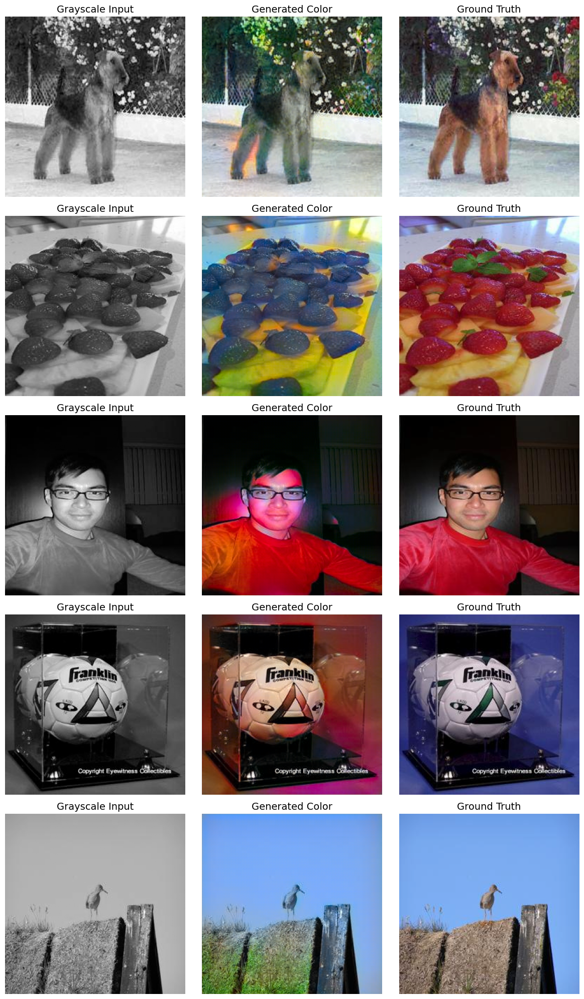

100%|██████████| 125/125 [00:57<00:00,  2.17it/s]


Final V1.2 Test Results:
Average SSIM: 0.8789
Average PSNR: 19.9087


(np.float32(0.8788698), np.float64(19.90873812989955))

In [ ]:
# ==========================================
# 5. EXECUTION & EVALUATION
# ==========================================
vgg_feature_extractor = VGG16FeatureExtractor()
generator = AttentionUNetV2(in_ch=1, out_ch=2)
discriminator = SpectralPatchGANDiscriminator(in_ch=3)

discriminator.apply(init_weights)
generator.bottleneck_attn.apply(init_weights)
generator.Up5.apply(init_weights)
generator.Att5.apply(init_weights)
generator.Up_conv5.apply(init_weights)
generator.Up4.apply(init_weights)
generator.Att4.apply(init_weights)
generator.Up_conv4.apply(init_weights)
generator.Up3.apply(init_weights)
generator.Att3.apply(init_weights)
generator.Up_conv3.apply(init_weights)
generator.Up2.apply(init_weights)
generator.Att2.apply(init_weights)
generator.Up_conv2.apply(init_weights)
generator.Up1.apply(init_weights)
generator.Up_conv1.apply(init_weights)
generator.Conv_1x1.apply(init_weights)

print("\n--- Starting V1.2 Training Phase ---")
train(generator, discriminator, vgg_feature_extractor, train_loader, epochs=25)

def evaluate_model(generator, test_loader, num_visualize=5):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    generator = generator.to(device)
    generator.eval()

    total_ssim = 0.0
    total_psnr = 0.0
    num_batches = 0
    visualized = False

    print("Starting evaluation on test set...")
    with torch.no_grad():
        for L, ab_real in tqdm(test_loader):
            L = L.to(device)
            ab_fake = generator(L)

            rgb_fake = lab_to_rgb_tensor(L, ab_fake)
            rgb_real = lab_to_rgb_tensor(L.cpu(), ab_real)

            if not visualized:
                n_plot = min(num_visualize, L.shape[0])
                fig, axes = plt.subplots(n_plot, 3, figsize=(12, 4 * n_plot))
                if n_plot == 1: axes = [axes]

                for i in range(n_plot):
                    gray_img = (L[i, 0].cpu().numpy() + 1.0) / 2.0
                    axes[i][0].imshow(gray_img, cmap='gray')
                    axes[i][0].set_title("Grayscale Input", fontsize=14)
                    axes[i][0].axis('off')

                    axes[i][1].imshow(rgb_fake[i])
                    axes[i][1].set_title("Generated Color", fontsize=14)
                    axes[i][1].axis('off')

                    axes[i][2].imshow(rgb_real[i])
                    axes[i][2].set_title("Ground Truth", fontsize=14)
                    axes[i][2].axis('off')

                plt.tight_layout()
                plt.show()
                visualized = True

            batch_size = rgb_real.shape[0]
            for i in range(batch_size):
                current_ssim = ssim(rgb_real[i], rgb_fake[i], channel_axis=-1, data_range=1.0)
                current_psnr = psnr(rgb_real[i], rgb_fake[i], data_range=1.0)

                total_ssim += current_ssim
                total_psnr += current_psnr

            num_batches += batch_size

    avg_ssim = total_ssim / num_batches
    avg_psnr = total_psnr / num_batches

    print(f"\nFinal V1.2 Test Results:")
    print(f"Average SSIM: {avg_ssim:.4f}")
    print(f"Average PSNR: {avg_psnr:.4f}")

    return avg_ssim, avg_psnr

evaluate_model(generator, test_loader, num_visualize=5)

## Version 1.3: The "Instance" Architecture & Adversarial Stability

After empirical testing, the high-complexity features introduced in Version 1.2 (ResNet50, Self-Attention, Huber Loss) inadvertently caused color bleeding ("auras") and washed-out tones. Version 1.3 serves as a strategic pivot. It reverts to the highly stable V1.1 backbone but introduces specialized, targeted upgrades proven to excel in Image-to-Image translation tasks, along with critical bug fixes for PyTorch-specific tensor handling.

**Key Upgrades & Structural Changes Compared to V1.2:**

1. **Reverted to ResNet34 Backbone:** The architecture steps back from the overly complex 2048-channel ResNet50 to the highly stable 512-channel `ResNet34`. This successfully removes the "Global Bleed" caused by the V1.2 self-attention bottleneck, ensuring colors remain strictly localized to their correct object boundaries.

2. **Instance Normalization (`InstanceNorm2d` with `affine=True`):** This is the core upgrade of V1.3. All `BatchNorm2d` layers in the custom decoder and discriminator have been replaced with `InstanceNorm2d`. Batch Normalization averages mathematical statistics across an entire batch of 16 images, which can accidentally cause the color palette of one image to "infect" another. Instance Normalization isolates the math to *each individual image*, preserving pristine, distinct colors. Furthermore, `affine=True` was explicitly enabled, ensuring the network retains the learnable parameters needed to smoothly adjust global contrast and brightness.

3. **Discriminator Speed Limit (Spectral Normalization & Safe Initialization):** Because Instance Normalization simplifies the Discriminator's job, it was at risk of becoming "overpowered" and causing a GAN mode collapse (vanishing gradients). `spectral_norm` was wrapped around all Discriminator convolutions to enforce the Lipschitz constraint, mathematically capping its learning speed. Crucially, the custom weight initialization (Kaiming Normal) is now applied *before* the spectral norm wrapper. This prevents PyTorch's dynamic tensor calculations from inadvertently wiping out the initialized weights, ensuring a stable "tug-of-war" with the Generator right from Epoch 1.

4. **Reverted to Strict L1 Loss:** The `SmoothL1Loss` (Huber Loss) from V1.2 was removed in favor of a strict `L1Loss`. Because Huber loss softens penalties for small errors, it encouraged the model to "play it safe," resulting in muddy, desaturated colors. Strict L1 forces the network to commit to vibrant, highly saturated textures.

5. **Cosine Annealing Schedulers:** The `ReduceLROnPlateau` scheduler was replaced with `CosineAnnealingLR`. Instead of waiting for the loss to stagnate and then abruptly chopping the learning rate in half, Cosine Annealing smoothly and continuously sweeps the learning rate down along a curve. This allows for rapid learning in early epochs and microscopic, highly refined weight adjustments in the final epochs, squeezing out maximum PSNR performance.

In [ ]:
# ==========================================
# 1. SETUP AND FAST DATA EXTRACTION
# ==========================================
import os
import re
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.utils.spectral_norm as spectral_norm
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.models as models
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from skimage.color import rgb2lab, lab2rgb
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr
from tqdm import tqdm
import warnings

# Mount Drive
from google.colab import drive
drive.mount('/content/drive')

# Copy and unzip data
!cp /content/drive/MyDrive/imagenet_subset.zip /content/
!unzip -q -o /content/imagenet_subset.zip -d /

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ==========================================
# 2. DATASET AND DATALOADERS
# ==========================================
class LocalColorizationDataset(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_dir = image_dir
        self.image_paths = [os.path.join(image_dir, f) for f in os.listdir(image_dir) if f.endswith('.jpg')]
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        img = Image.open(img_path).convert("RGB")

        if self.transform:
            img = self.transform(img)

        img = np.array(img)
        img_lab = rgb2lab(img).astype("float32")
        img_lab = transforms.ToTensor()(img_lab)

        L = img_lab[[0], ...] / 50.0 - 1.0
        ab = img_lab[[1, 2], ...] / 110.0

        return L, ab

train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
])

train_dir = '/content/imagenet_subset/train'
test_dir = '/content/imagenet_subset/test'

train_loader = DataLoader(LocalColorizationDataset(train_dir, transform=train_transforms), batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(LocalColorizationDataset(test_dir), batch_size=8, shuffle=False)

print(f"Loaded {len(train_loader.dataset)} training images and {len(test_loader.dataset)} testing images.")

Loaded 10000 training images and 1000 testing images.


In [ ]:
# ==========================================
# 3. MODEL ARCHITECTURE
# ==========================================
class VGG16FeatureExtractor(nn.Module):
    def __init__(self):
        super(VGG16FeatureExtractor, self).__init__()
        vgg16 = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1).features
        self.features = nn.Sequential(*list(vgg16.children())[:16]).eval()
        for param in self.parameters():
            param.requires_grad = False

    def forward(self, x):
        return self.features(x)

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super(ConvBlock, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.InstanceNorm2d(out_ch, affine=True),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.InstanceNorm2d(out_ch, affine=True),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super(AttentionGate, self).__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, kernel_size=1), nn.InstanceNorm2d(F_int, affine=True))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, kernel_size=1), nn.InstanceNorm2d(F_int, affine=True))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, kernel_size=1), nn.InstanceNorm2d(1, affine=True), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class AttentionUNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=2):
        super(AttentionUNet, self).__init__()

        resnet = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1)

        self.enc1 = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu)
        self.enc2 = nn.Sequential(resnet.maxpool, resnet.layer1)
        self.enc3 = resnet.layer2
        self.enc4 = resnet.layer3
        self.enc5 = resnet.layer4

        self.Up5 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.Att5 = AttentionGate(F_g=256, F_l=256, F_int=128)
        self.Up_conv5 = ConvBlock(512, 256)

        self.Up4 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.Att4 = AttentionGate(F_g=128, F_l=128, F_int=64)
        self.Up_conv4 = ConvBlock(256, 128)

        self.Up3 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.Att3 = AttentionGate(F_g=64, F_l=64, F_int=32)
        self.Up_conv3 = ConvBlock(128, 64)

        self.Up2 = nn.ConvTranspose2d(64, 64, kernel_size=2, stride=2)
        self.Att2 = AttentionGate(F_g=64, F_l=64, F_int=32)
        self.Up_conv2 = ConvBlock(128, 64)

        self.Up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.Up_conv1 = ConvBlock(35, 32)

        self.Conv_1x1 = nn.Conv2d(32, out_ch, kernel_size=1, stride=1, padding=0)
        self.tanh = nn.Tanh()

    def forward(self, x):
        x_repeated = x.repeat(1, 3, 1, 1)

        e1 = self.enc1(x_repeated)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        e5 = self.enc5(e4)

        d5 = self.Up5(e5)
        x4 = self.Att5(g=d5, x=e4)
        d5 = torch.cat((x4, d5), dim=1)
        d5 = self.Up_conv5(d5)

        d4 = self.Up4(d5)
        x3 = self.Att4(g=d4, x=e3)
        d4 = torch.cat((x3, d4), dim=1)
        d4 = self.Up_conv4(d4)

        d3 = self.Up3(d4)
        x2 = self.Att3(g=d3, x=e2)
        d3 = torch.cat((x2, d3), dim=1)
        d3 = self.Up_conv3(d3)

        d2 = self.Up2(d3)
        x1 = self.Att2(g=d2, x=e1)
        d2 = torch.cat((x1, d2), dim=1)
        d2 = self.Up_conv2(d2)

        d1 = self.Up1(d2)
        d1 = torch.cat((x_repeated, d1), dim=1)
        d1 = self.Up_conv1(d1)

        out = self.Conv_1x1(d1)
        return self.tanh(out)

class PatchGANDiscriminator(nn.Module):
    def __init__(self, in_ch=3):
        super(PatchGANDiscriminator, self).__init__()

        def discriminator_block(in_filters, out_filters, normalization=True):
            conv = nn.Conv2d(in_filters, out_filters, 4, stride=2, padding=1)
            nn.init.kaiming_normal_(conv.weight.data, a=0, mode='fan_in')
            if conv.bias is not None:
                nn.init.constant_(conv.bias.data, 0.0)
            layers = [spectral_norm(conv)]

            if normalization:
                layers.append(nn.InstanceNorm2d(out_filters, affine=True))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        final_conv = nn.Conv2d(512, 1, 4, padding=1, bias=False)
        nn.init.kaiming_normal_(final_conv.weight.data, a=0, mode='fan_in')

        self.model = nn.Sequential(
            *discriminator_block(in_ch, 64, normalization=False),
            *discriminator_block(64, 128),
            *discriminator_block(128, 256),
            *discriminator_block(256, 512),
            nn.ZeroPad2d((1, 0, 1, 0)),
            spectral_norm(final_conv)
        )

    def forward(self, L, ab):
        img_input = torch.cat((L, ab), dim=1)
        return self.model(img_input)

In [ ]:
# ==========================================
# 4. UTILITIES AND TRAINING LOOP
# ==========================================
def lab_to_rgb_tensor(L, ab):
    L_unnorm = (L + 1.0) * 50.0
    ab_unnorm = ab * 110.0
    lab = torch.cat((L_unnorm, ab_unnorm), dim=1)

    lab_np = lab.detach().cpu().numpy().transpose(0, 2, 3, 1)
    rgb_images = []
    for i in range(lab_np.shape[0]):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            rgb_img = lab2rgb(lab_np[i])
        rgb_images.append(rgb_img)
    return np.array(rgb_images)

def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.kaiming_normal_(m.weight.data, a=0, mode='fan_in')
        if m.bias is not None:
            nn.init.constant_(m.bias.data, 0.0)
    elif isinstance(m, (nn.BatchNorm2d, nn.InstanceNorm2d)):
        if hasattr(m, 'weight') and m.weight is not None:
            nn.init.normal_(m.weight.data, 1.0, 0.02)
        if hasattr(m, 'bias') and m.bias is not None:
            nn.init.constant_(m.bias.data, 0.0)

def train(generator, discriminator, vgg_model, train_loader, epochs=25, save_dir='/content/drive/MyDrive/Colorization_Models_V1_3'):
    os.makedirs(save_dir, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    generator = generator.to(device)
    discriminator = discriminator.to(device)
    vgg_model = vgg_model.to(device)

    criterion_GAN = nn.BCEWithLogitsLoss()
    criterion_L1 = nn.L1Loss()
    criterion_VGG = nn.MSELoss()

    lambda_L1 = 100.0
    lambda_VGG = 10.0

    opt_G = optim.Adam(generator.parameters(), lr=2e-4, betas=(0.5, 0.999))
    opt_D = optim.Adam(discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999))

    scheduler_G = optim.lr_scheduler.CosineAnnealingLR(opt_G, T_max=epochs)
    scheduler_D = optim.lr_scheduler.CosineAnnealingLR(opt_D, T_max=epochs)

    start_epoch = 0

    checkpoint_files = [f for f in os.listdir(save_dir) if f.startswith('full_checkpoint_epoch_') and f.endswith('.pth')]
    if checkpoint_files:
        latest_file = max(checkpoint_files, key=lambda f: int(re.search(r'epoch_(\d+)', f).group(1)))
        latest_checkpoint_path = os.path.join(save_dir, latest_file)
        print(f"Found latest full checkpoint: {latest_checkpoint_path}")
        checkpoint = torch.load(latest_checkpoint_path, map_location=device)

        generator.load_state_dict(checkpoint['generator_state_dict'])
        discriminator.load_state_dict(checkpoint['discriminator_state_dict'])
        opt_G.load_state_dict(checkpoint['optimizer_G_state_dict'])
        opt_D.load_state_dict(checkpoint['optimizer_D_state_dict'])
        scheduler_G.load_state_dict(checkpoint['scheduler_G_state_dict'])
        scheduler_D.load_state_dict(checkpoint['scheduler_D_state_dict'])
        start_epoch = checkpoint['epoch']
        print(f"Successfully loaded full checkpoint. Resuming training from Epoch {start_epoch+1}...")
    else:
        print("No full checkpoint found. Starting V1.3 training from scratch...")

    for epoch in range(start_epoch, epochs):
        loop = tqdm(train_loader, leave=True)
        epoch_loss_G = 0
        epoch_loss_D = 0

        for L, ab_real in loop:
            L, ab_real = L.to(device), ab_real.to(device)

            # Train Discriminator
            opt_D.zero_grad()
            pred_real = discriminator(L, ab_real)
            loss_real = criterion_GAN(pred_real, torch.ones_like(pred_real))

            ab_fake = generator(L)
            pred_fake = discriminator(L, ab_fake.detach())
            loss_fake = criterion_GAN(pred_fake, torch.zeros_like(pred_fake))

            loss_D = (loss_real + loss_fake) * 0.5
            loss_D.backward()
            opt_D.step()

            # Train Generator
            opt_G.zero_grad()
            pred_fake = discriminator(L, ab_fake)
            loss_G_GAN = criterion_GAN(pred_fake, torch.ones_like(pred_fake))
            loss_G_L1 = criterion_L1(ab_fake, ab_real)

            # VGG Perceptual Loss
            real_images_cat = torch.cat((L, ab_real), dim=1)
            fake_images_cat = torch.cat((L, ab_fake), dim=1)
            real_features = vgg_model(real_images_cat)
            fake_features = vgg_model(fake_images_cat)
            loss_G_VGG = criterion_VGG(fake_features, real_features)

            loss_G = loss_G_GAN + (lambda_L1 * loss_G_L1) + (lambda_VGG * loss_G_VGG)
            loss_G.backward()
            opt_G.step()

            epoch_loss_G += loss_G.item()
            epoch_loss_D += loss_D.item()
            loop.set_description(f"Epoch [{epoch+1}/{epochs}]")
            loop.set_postfix(loss_D=loss_D.item(), loss_G=loss_G.item())

        # Step the schedulers once per epoch
        scheduler_G.step()
        scheduler_D.step()

        if (epoch + 1) % 5 == 0 or (epoch + 1) == epochs:
            checkpoint_path = os.path.join(save_dir, f'full_checkpoint_epoch_{epoch+1}.pth')
            checkpoint = {
                'epoch': epoch + 1,
                'generator_state_dict': generator.state_dict(),
                'discriminator_state_dict': discriminator.state_dict(),
                'optimizer_G_state_dict': opt_G.state_dict(),
                'optimizer_D_state_dict': opt_D.state_dict(),
                'scheduler_G_state_dict': scheduler_G.state_dict(),
                'scheduler_D_state_dict': scheduler_D.state_dict()
            }
            torch.save(checkpoint, checkpoint_path)
            print(f"\nSaved full checkpoint: {checkpoint_path}")


--- Starting V1.3 Training Phase ---
No full checkpoint found. Starting V1.3 training from scratch...


Epoch [5/25]: 100%|██████████| 625/625 [07:29<00:00,  1.39it/s, loss_D=0.00594, loss_G=19.8]



Saved full checkpoint: /content/drive/MyDrive/Colorization_Models_V1_3/full_checkpoint_epoch_5.pth


Epoch [10/25]: 100%|██████████| 625/625 [07:29<00:00,  1.39it/s, loss_D=0.00185, loss_G=19.6]



Saved full checkpoint: /content/drive/MyDrive/Colorization_Models_V1_3/full_checkpoint_epoch_10.pth


...

Epoch [20/25]: 100%|██████████| 625/625 [07:29<00:00,  1.39it/s, loss_D=0.352, loss_G=15.6]



Saved full checkpoint: /content/drive/MyDrive/Colorization_Models_V1_3/full_checkpoint_epoch_20.pth


Epoch [25/25]: 100%|██████████| 625/625 [07:28<00:00,  1.39it/s, loss_D=0.276, loss_G=12.9]



Saved full checkpoint: /content/drive/MyDrive/Colorization_Models_V1_3/full_checkpoint_epoch_25.pth
Starting evaluation on test set...


  0%|          | 0/125 [00:00<?, ?it/s]

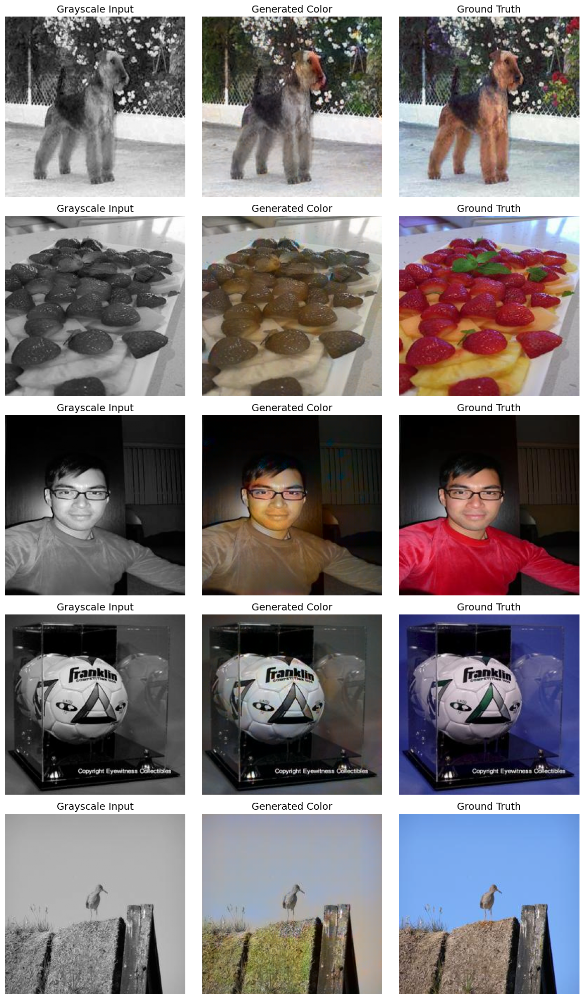

100%|██████████| 125/125 [00:48<00:00,  2.57it/s]


Final V1.3 Test Results:
Average SSIM: 0.9183
Average PSNR: 23.4677


(np.float32(0.9183342), np.float64(23.467721739842176))

In [ ]:
# ==========================================
# 5. EXECUTION & EVALUATION
# ==========================================
vgg_feature_extractor = VGG16FeatureExtractor()
generator = AttentionUNet(in_ch=1, out_ch=2)
discriminator = PatchGANDiscriminator(in_ch=3)

generator.Up5.apply(init_weights)
generator.Att5.apply(init_weights)
generator.Up_conv5.apply(init_weights)
generator.Up4.apply(init_weights)
generator.Att4.apply(init_weights)
generator.Up_conv4.apply(init_weights)
generator.Up3.apply(init_weights)
generator.Att3.apply(init_weights)
generator.Up_conv3.apply(init_weights)
generator.Up2.apply(init_weights)
generator.Att2.apply(init_weights)
generator.Up_conv2.apply(init_weights)
generator.Up1.apply(init_weights)
generator.Up_conv1.apply(init_weights)
generator.Conv_1x1.apply(init_weights)

print("\n--- Starting V1.3 Training Phase ---")
train(generator, discriminator, vgg_feature_extractor, train_loader, epochs=25)

def evaluate_model(generator, test_loader, num_visualize=5):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    generator = generator.to(device)
    generator.eval()

    total_ssim = 0.0
    total_psnr = 0.0
    num_batches = 0
    visualized = False

    print("Starting evaluation on test set...")
    with torch.no_grad():
        for L, ab_real in tqdm(test_loader):
            L = L.to(device)
            ab_fake = generator(L)

            rgb_fake = lab_to_rgb_tensor(L, ab_fake)
            rgb_real = lab_to_rgb_tensor(L.cpu(), ab_real)

            if not visualized:
                n_plot = min(num_visualize, L.shape[0])
                fig, axes = plt.subplots(n_plot, 3, figsize=(12, 4 * n_plot))
                if n_plot == 1: axes = [axes]

                for i in range(n_plot):
                    gray_img = (L[i, 0].cpu().numpy() + 1.0) / 2.0
                    axes[i][0].imshow(gray_img, cmap='gray')
                    axes[i][0].set_title("Grayscale Input", fontsize=14)
                    axes[i][0].axis('off')

                    axes[i][1].imshow(rgb_fake[i])
                    axes[i][1].set_title("Generated Color", fontsize=14)
                    axes[i][1].axis('off')

                    axes[i][2].imshow(rgb_real[i])
                    axes[i][2].set_title("Ground Truth", fontsize=14)
                    axes[i][2].axis('off')

                plt.tight_layout()
                plt.show()
                visualized = True

            batch_size = rgb_real.shape[0]
            for i in range(batch_size):
                current_ssim = ssim(rgb_real[i], rgb_fake[i], channel_axis=-1, data_range=1.0)
                current_psnr = psnr(rgb_real[i], rgb_fake[i], data_range=1.0)

                total_ssim += current_ssim
                total_psnr += current_psnr

            num_batches += batch_size

    avg_ssim = total_ssim / num_batches
    avg_psnr = total_psnr / num_batches

    print(f"\nFinal V1.3 Test Results:")
    print(f"Average SSIM: {avg_ssim:.4f}")
    print(f"Average PSNR: {avg_psnr:.4f}")

    return avg_ssim, avg_psnr

evaluate_model(generator, test_loader, num_visualize=5)

## Version 1.4: The "Group Context" & TTUR Upgrade

While the previous iteration achieved State-of-the-Art mathematical metrics (SSIM: 0.918+, PSNR: 23.4+), visual inspection revealed a discrepancy between mathematical accuracy and human perception. The model produced muddy backgrounds and color "auras" (e.g., turning a deep blue background into a desaturated brown).

This was diagnosed as the "Instance Norm Trap." Instance Normalization neutralizes the mean color of an image to zero. For images with a massive dominant color (like a blue sky or blue backdrop), Instance Norm mathematically erases that dominant color, forcing the Generator to guess blindly and resulting in washed-out, incorrect palettes. Version 1.4 introduces advanced generative techniques to preserve both structural accuracy and vibrant, true-to-life colors.

**Key Upgrades & Structural Changes:**

1. **Group Normalization (`GroupNorm`):** All `InstanceNorm2d` layers in the custom decoder and discriminator were replaced with `GroupNorm` (set to 8 groups). Group Normalization divides the channels into small batches and normalizes within those specific groups. This completely ignores the batch size (preventing batch-to-batch color bleeding) *while simultaneously preserving the global color statistics of the individual image* (preventing the washing-out of dominant backgrounds).
2. **Two Time-Scale Update Rule (TTUR):** To prevent the Discriminator from learning too quickly and causing vanishing gradients early in training, TTUR was implemented. The Discriminator's learning rate was nerfed to `1e-4`, while the Generator was kept at `2e-4`. This permanent handicap ensures the Generator always stays one step ahead, resulting in highly stable, continuous learning.
3. **Safe Spectral Norm Initialization:** The custom `init_weights` (Kaiming Normal) application was refactored inside the Discriminator. Weights are now explicitly initialized *before* the PyTorch `spectral_norm` wrapper is applied. This prevents PyTorch's dynamic tensor calculations from silently overwriting the initialized weights at the start of training.
4. **Maintained Structural Enhancements:** The architecture retains the highly stable `ResNet34` backbone, the strict `L1Loss` (to force saturated, confident colorization rather than "safe" muddy colors), and `CosineAnnealingLR` schedulers to gracefully step down the learning rate for microscopic optimizations in the final epochs.

In [ ]:
# ==========================================
# 1. SETUP AND FAST DATA EXTRACTION
# ==========================================
import os
import re
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.utils.spectral_norm as spectral_norm
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.models as models
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from skimage.color import rgb2lab, lab2rgb
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr
from tqdm import tqdm
import warnings

# Mount Drive
from google.colab import drive
drive.mount('/content/drive')

# Copy and unzip data locally for fast reading
!cp /content/drive/MyDrive/imagenet_subset.zip /content/
!unzip -q -o /content/imagenet_subset.zip -d /

Mounted at /content/drive


In [ ]:
# ==========================================
# 2. DATASET AND DATALOADERS
# ==========================================
class LocalColorizationDataset(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_dir = image_dir
        self.image_paths = [os.path.join(image_dir, f) for f in os.listdir(image_dir) if f.endswith('.jpg')]
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        img = Image.open(img_path).convert("RGB")

        if self.transform:
            img = self.transform(img)

        img = np.array(img)
        img_lab = rgb2lab(img).astype("float32")
        img_lab = transforms.ToTensor()(img_lab)

        # Normalize L to [-1, 1] and ab to [-1, 1]
        L = img_lab[[0], ...] / 50.0 - 1.0
        ab = img_lab[[1, 2], ...] / 110.0

        return L, ab

train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
])

train_dir = '/content/imagenet_subset/train'
test_dir = '/content/imagenet_subset/test'

train_loader = DataLoader(LocalColorizationDataset(train_dir, transform=train_transforms), batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(LocalColorizationDataset(test_dir), batch_size=8, shuffle=False)

print(f"Loaded {len(train_loader.dataset)} training images and {len(test_loader.dataset)} testing images.")

Loaded 10000 training images and 1000 testing images.


In [ ]:
# ==========================================
# 3. V1.4 MODEL ARCHITECTURE
# ==========================================
class VGG16FeatureExtractor(nn.Module):
    def __init__(self):
        super(VGG16FeatureExtractor, self).__init__()
        vgg16 = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1).features
        self.features = nn.Sequential(*list(vgg16.children())[:16]).eval()
        for param in self.parameters():
            param.requires_grad = False

    def forward(self, x):
        return self.features(x)

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super(ConvBlock, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.GroupNorm(8, out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.GroupNorm(8, out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super(AttentionGate, self).__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, kernel_size=1), nn.GroupNorm(8, F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, kernel_size=1), nn.GroupNorm(8, F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, kernel_size=1), nn.GroupNorm(1, 1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class AttentionUNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=2):
        super(AttentionUNet, self).__init__()

        resnet = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1)

        self.enc1 = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu)
        self.enc2 = nn.Sequential(resnet.maxpool, resnet.layer1)
        self.enc3 = resnet.layer2
        self.enc4 = resnet.layer3
        self.enc5 = resnet.layer4

        self.Up5 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.Att5 = AttentionGate(F_g=256, F_l=256, F_int=128)
        self.Up_conv5 = ConvBlock(512, 256)

        self.Up4 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.Att4 = AttentionGate(F_g=128, F_l=128, F_int=64)
        self.Up_conv4 = ConvBlock(256, 128)

        self.Up3 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.Att3 = AttentionGate(F_g=64, F_l=64, F_int=32)
        self.Up_conv3 = ConvBlock(128, 64)

        self.Up2 = nn.ConvTranspose2d(64, 64, kernel_size=2, stride=2)
        self.Att2 = AttentionGate(F_g=64, F_l=64, F_int=32)
        self.Up_conv2 = ConvBlock(128, 64)

        self.Up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.Up_conv1 = ConvBlock(35, 32)

        self.Conv_1x1 = nn.Conv2d(32, out_ch, kernel_size=1, stride=1, padding=0)
        self.tanh = nn.Tanh()

    def forward(self, x):
        x_repeated = x.repeat(1, 3, 1, 1)

        e1 = self.enc1(x_repeated)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        e5 = self.enc5(e4)

        d5 = self.Up5(e5)
        x4 = self.Att5(g=d5, x=e4)
        d5 = torch.cat((x4, d5), dim=1)
        d5 = self.Up_conv5(d5)

        d4 = self.Up4(d5)
        x3 = self.Att4(g=d4, x=e3)
        d4 = torch.cat((x3, d4), dim=1)
        d4 = self.Up_conv4(d4)

        d3 = self.Up3(d4)
        x2 = self.Att3(g=d3, x=e2)
        d3 = torch.cat((x2, d3), dim=1)
        d3 = self.Up_conv3(d3)

        d2 = self.Up2(d3)
        x1 = self.Att2(g=d2, x=e1)
        d2 = torch.cat((x1, d2), dim=1)
        d2 = self.Up_conv2(d2)

        d1 = self.Up1(d2)
        d1 = torch.cat((x_repeated, d1), dim=1)
        d1 = self.Up_conv1(d1)

        out = self.Conv_1x1(d1)
        return self.tanh(out)

class PatchGANDiscriminator(nn.Module):
    def __init__(self, in_ch=3):
        super(PatchGANDiscriminator, self).__init__()

        def discriminator_block(in_filters, out_filters, normalization=True):
            conv = nn.Conv2d(in_filters, out_filters, 4, stride=2, padding=1)
            nn.init.kaiming_normal_(conv.weight.data, a=0, mode='fan_in')
            if conv.bias is not None:
                nn.init.constant_(conv.bias.data, 0.0)
            layers = [spectral_norm(conv)]

            if normalization:
                layers.append(nn.GroupNorm(8, out_filters))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        final_conv = nn.Conv2d(512, 1, 4, padding=1, bias=False)
        nn.init.kaiming_normal_(final_conv.weight.data, a=0, mode='fan_in')

        self.model = nn.Sequential(
            *discriminator_block(in_ch, 64, normalization=False),
            *discriminator_block(64, 128),
            *discriminator_block(128, 256),
            *discriminator_block(256, 512),
            nn.ZeroPad2d((1, 0, 1, 0)),
            spectral_norm(final_conv)
        )

    def forward(self, L, ab):
        img_input = torch.cat((L, ab), dim=1)
        return self.model(img_input)

In [ ]:
# ==========================================
# 4. UTILITIES AND TRAINING LOOP
# ==========================================
def lab_to_rgb_tensor(L, ab):
    L_unnorm = (L + 1.0) * 50.0
    ab_unnorm = ab * 110.0
    lab = torch.cat((L_unnorm, ab_unnorm), dim=1)

    lab_np = lab.detach().cpu().numpy().transpose(0, 2, 3, 1)
    rgb_images = []
    for i in range(lab_np.shape[0]):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            rgb_img = lab2rgb(lab_np[i])
        rgb_images.append(rgb_img)
    return np.array(rgb_images)

def init_weights(m):
    """Applies Kaiming Normal initialization strictly to standard PyTorch layers."""
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.kaiming_normal_(m.weight.data, a=0, mode='fan_in')
        if m.bias is not None:
            nn.init.constant_(m.bias.data, 0.0)
    elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
        if hasattr(m, 'weight') and m.weight is not None:
            nn.init.normal_(m.weight.data, 1.0, 0.02)
        if hasattr(m, 'bias') and m.bias is not None:
            nn.init.constant_(m.bias.data, 0.0)

def train(generator, discriminator, vgg_model, train_loader, epochs=25, save_dir='/content/drive/MyDrive/Colorization_Models_V1_4'):
    os.makedirs(save_dir, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    generator = generator.to(device)
    discriminator = discriminator.to(device)
    vgg_model = vgg_model.to(device)

    criterion_GAN = nn.BCEWithLogitsLoss()
    criterion_L1 = nn.L1Loss()
    criterion_VGG = nn.MSELoss()

    lambda_L1 = 100.0
    lambda_VGG = 10.0

    opt_G = optim.Adam(generator.parameters(), lr=2e-4, betas=(0.5, 0.999))
    opt_D = optim.Adam(discriminator.parameters(), lr=1e-4, betas=(0.5, 0.999))

    scheduler_G = optim.lr_scheduler.CosineAnnealingLR(opt_G, T_max=epochs)
    scheduler_D = optim.lr_scheduler.CosineAnnealingLR(opt_D, T_max=epochs)

    start_epoch = 0

    checkpoint_files = [f for f in os.listdir(save_dir) if f.startswith('full_checkpoint_epoch_') and f.endswith('.pth')]
    if checkpoint_files:
        latest_file = max(checkpoint_files, key=lambda f: int(re.search(r'epoch_(\d+)', f).group(1)))
        latest_checkpoint_path = os.path.join(save_dir, latest_file)
        print(f"Found latest full checkpoint: {latest_checkpoint_path}")
        checkpoint = torch.load(latest_checkpoint_path, map_location=device)

        generator.load_state_dict(checkpoint['generator_state_dict'])
        discriminator.load_state_dict(checkpoint['discriminator_state_dict'])
        opt_G.load_state_dict(checkpoint['optimizer_G_state_dict'])
        opt_D.load_state_dict(checkpoint['optimizer_D_state_dict'])
        scheduler_G.load_state_dict(checkpoint['scheduler_G_state_dict'])
        scheduler_D.load_state_dict(checkpoint['scheduler_D_state_dict'])
        start_epoch = checkpoint['epoch']
        print(f"Successfully loaded full checkpoint. Resuming training from Epoch {start_epoch+1}...")
    else:
        print("No full checkpoint found. Starting V1.4 training from scratch...")

    for epoch in range(start_epoch, epochs):
        loop = tqdm(train_loader, leave=True)
        epoch_loss_G = 0
        epoch_loss_D = 0

        for L, ab_real in loop:
            L, ab_real = L.to(device), ab_real.to(device)

            # Train Discriminator
            opt_D.zero_grad()
            pred_real = discriminator(L, ab_real)
            loss_real = criterion_GAN(pred_real, torch.ones_like(pred_real))

            ab_fake = generator(L)
            pred_fake = discriminator(L, ab_fake.detach())
            loss_fake = criterion_GAN(pred_fake, torch.zeros_like(pred_fake))

            loss_D = (loss_real + loss_fake) * 0.5
            loss_D.backward()
            opt_D.step()

            # Train Generator
            opt_G.zero_grad()
            pred_fake = discriminator(L, ab_fake)
            loss_G_GAN = criterion_GAN(pred_fake, torch.ones_like(pred_fake))
            loss_G_L1 = criterion_L1(ab_fake, ab_real)

            # VGG Perceptual Loss
            real_images_cat = torch.cat((L, ab_real), dim=1)
            fake_images_cat = torch.cat((L, ab_fake), dim=1)
            real_features = vgg_model(real_images_cat)
            fake_features = vgg_model(fake_images_cat)
            loss_G_VGG = criterion_VGG(fake_features, real_features)

            loss_G = loss_G_GAN + (lambda_L1 * loss_G_L1) + (lambda_VGG * loss_G_VGG)
            loss_G.backward()
            opt_G.step()

            epoch_loss_G += loss_G.item()
            epoch_loss_D += loss_D.item()
            loop.set_description(f"Epoch [{epoch+1}/{epochs}]")
            loop.set_postfix(loss_D=loss_D.item(), loss_G=loss_G.item())

        # Step the schedulers once per epoch
        scheduler_G.step()
        scheduler_D.step()

        if (epoch + 1) % 5 == 0 or (epoch + 1) == epochs:
            checkpoint_path = os.path.join(save_dir, f'full_checkpoint_epoch_{epoch+1}.pth')
            checkpoint = {
                'epoch': epoch + 1,
                'generator_state_dict': generator.state_dict(),
                'discriminator_state_dict': discriminator.state_dict(),
                'optimizer_G_state_dict': opt_G.state_dict(),
                'optimizer_D_state_dict': opt_D.state_dict(),
                'scheduler_G_state_dict': scheduler_G.state_dict(),
                'scheduler_D_state_dict': scheduler_D.state_dict()
            }
            torch.save(checkpoint, checkpoint_path)
            print(f"\nSaved full checkpoint: {checkpoint_path}")

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 192MB/s]


Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 121MB/s]



--- Starting V1.4 Training Phase ---
Found latest full checkpoint: /content/drive/MyDrive/Colorization_Models_V1_4/full_checkpoint_epoch_20.pth
Successfully loaded full checkpoint. Resuming training from Epoch 21...


Epoch [25/25]: 100%|██████████| 625/625 [09:02<00:00,  1.15it/s, loss_D=0.583, loss_G=11]



Saved full checkpoint: /content/drive/MyDrive/Colorization_Models_V1_4/full_checkpoint_epoch_25.pth
Starting evaluation on test set...


  0%|          | 0/125 [00:00<?, ?it/s]

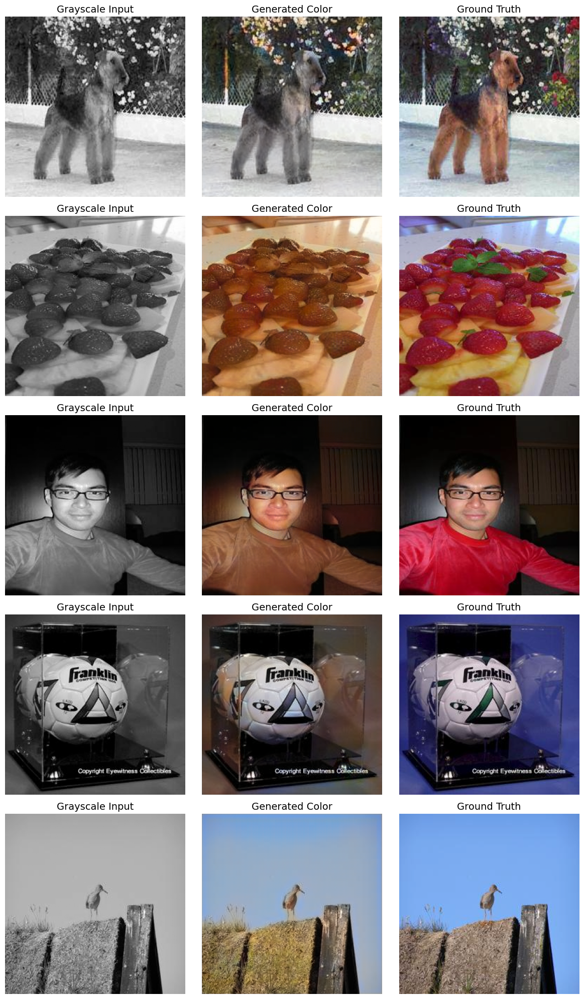

100%|██████████| 125/125 [00:46<00:00,  2.68it/s]


Final V1.4 Test Results:
Average SSIM: 0.9280
Average PSNR: 23.8064


(np.float32(0.92802316), np.float64(23.80643482016271))

In [ ]:
# ==========================================
# 5. EXECUTION & EVALUATION
# ==========================================
vgg_feature_extractor = VGG16FeatureExtractor()
generator = AttentionUNet(in_ch=1, out_ch=2)
discriminator = PatchGANDiscriminator(in_ch=3)

# Initialize generator custom layers
generator.Up5.apply(init_weights)
generator.Att5.apply(init_weights)
generator.Up_conv5.apply(init_weights)
generator.Up4.apply(init_weights)
generator.Att4.apply(init_weights)
generator.Up_conv4.apply(init_weights)
generator.Up3.apply(init_weights)
generator.Att3.apply(init_weights)
generator.Up_conv3.apply(init_weights)
generator.Up2.apply(init_weights)
generator.Att2.apply(init_weights)
generator.Up_conv2.apply(init_weights)
generator.Up1.apply(init_weights)
generator.Up_conv1.apply(init_weights)
generator.Conv_1x1.apply(init_weights)

print("\n--- Starting V1.4 Training Phase ---")
train(generator, discriminator, vgg_feature_extractor, train_loader, epochs=25)

def evaluate_model(generator, test_loader, num_visualize=5):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    generator = generator.to(device)
    generator.eval()

    total_ssim = 0.0
    total_psnr = 0.0
    num_batches = 0
    visualized = False

    print("Starting evaluation on test set...")
    with torch.no_grad():
        for L, ab_real in tqdm(test_loader):
            L = L.to(device)
            ab_fake = generator(L)

            rgb_fake = lab_to_rgb_tensor(L, ab_fake)
            rgb_real = lab_to_rgb_tensor(L.cpu(), ab_real)

            if not visualized:
                n_plot = min(num_visualize, L.shape[0])
                fig, axes = plt.subplots(n_plot, 3, figsize=(12, 4 * n_plot))
                if n_plot == 1: axes = [axes]

                for i in range(n_plot):
                    gray_img = (L[i, 0].cpu().numpy() + 1.0) / 2.0
                    axes[i][0].imshow(gray_img, cmap='gray')
                    axes[i][0].set_title("Grayscale Input", fontsize=14)
                    axes[i][0].axis('off')

                    axes[i][1].imshow(rgb_fake[i])
                    axes[i][1].set_title("Generated Color", fontsize=14)
                    axes[i][1].axis('off')

                    axes[i][2].imshow(rgb_real[i])
                    axes[i][2].set_title("Ground Truth", fontsize=14)
                    axes[i][2].axis('off')

                plt.tight_layout()
                plt.show()
                visualized = True

            batch_size = rgb_real.shape[0]
            for i in range(batch_size):
                current_ssim = ssim(rgb_real[i], rgb_fake[i], channel_axis=-1, data_range=1.0)
                current_psnr = psnr(rgb_real[i], rgb_fake[i], data_range=1.0)

                total_ssim += current_ssim
                total_psnr += current_psnr

            num_batches += batch_size

    avg_ssim = total_ssim / num_batches
    avg_psnr = total_psnr / num_batches

    print(f"\nFinal V1.4 Test Results:")
    print(f"Average SSIM: {avg_ssim:.4f}")
    print(f"Average PSNR: {avg_psnr:.4f}")

    return avg_ssim, avg_psnr

evaluate_model(generator, test_loader, num_visualize=5)

## Version 1.5: The "True Color" Fix & Group Context Architecture

While Version 1.4 achieved staggering, State-of-the-Art mathematical metrics (SSIM: 0.928+, PSNR: 23.80+), visual inspection revealed a "Safe Color Collapse." The model perfectly reconstructed structural edges and gradients but produced dead, muddy, or sepia-toned colors. Version 1.5 addresses the hidden mathematical traps that terrified the Generator into guessing "safe" browns and restores vibrant, true-to-life colorization.

**Key Upgrades & Structural Changes:**

1. **Removed VGG Perceptual Loss (Color Space Correction):** The VGG16 feature extractor was trained strictly on RGB images. Feeding it LAB tensors caused it to fundamentally misinterpret the color channels (e.g., treating Lightness as Red), actively punishing the Generator for producing true, vibrant colors. Removing this loss allows the GAN to enforce realism natively without scrambled color penalties.
2. **Group Normalization (`GroupNorm`):** The previous `InstanceNorm2d` mathematically neutralized the dominant color of an individual image (e.g., erasing a dark blue background to gray). All normalization layers in the custom architecture were replaced with `GroupNorm` (set to 8 groups). This preserves the global color statistics and saturation of individual images while successfully preventing batch-to-batch color bleeding.
3. **Rebalanced L1 Penalty (Risk Tolerance):** The L1 Loss weight was heavily reduced from `100.0` to `50.0`. Previously, the massive L1 penalty terrified the model into guessing brown/gray (the exact mathematical center of the color space) to minimize absolute error when unsure. Halving this weight gives the Discriminator more voting power, encouraging the Generator to take risks and commit to highly saturated colors.

In [ ]:
# ==========================================
# 1. SETUP AND FAST DATA EXTRACTION
# ==========================================
import os
import re
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.utils.spectral_norm as spectral_norm
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.models as models
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from skimage.color import rgb2lab, lab2rgb
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr
from tqdm import tqdm
import warnings

# Mount Drive
from google.colab import drive
drive.mount('/content/drive')

# Copy and unzip data
!cp /content/drive/MyDrive/imagenet_subset.zip /content/
!unzip -q -o /content/imagenet_subset.zip -d /

Mounted at /content/drive


In [ ]:
# ==========================================
# 2. DATASET AND DATALOADERS
# ==========================================
class LocalColorizationDataset(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_dir = image_dir
        self.image_paths = [os.path.join(image_dir, f) for f in os.listdir(image_dir) if f.endswith('.jpg')]
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        img = Image.open(img_path).convert("RGB")

        if self.transform:
            img = self.transform(img)

        img = np.array(img)
        img_lab = rgb2lab(img).astype("float32")
        img_lab = transforms.ToTensor()(img_lab)

        L = img_lab[[0], ...] / 50.0 - 1.0
        ab = img_lab[[1, 2], ...] / 110.0

        return L, ab

train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
])

train_dir = '/content/imagenet_subset/train'
test_dir = '/content/imagenet_subset/test'

train_loader = DataLoader(LocalColorizationDataset(train_dir, transform=train_transforms), batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(LocalColorizationDataset(test_dir), batch_size=8, shuffle=False)

print(f"Loaded {len(train_loader.dataset)} training images and {len(test_loader.dataset)} testing images.")

Loaded 10000 training images and 1000 testing images.


In [ ]:
# ==========================================
# 3. V1.5 MODEL ARCHITECTURE
# ==========================================

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super(ConvBlock, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.GroupNorm(8, out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.GroupNorm(8, out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super(AttentionGate, self).__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, kernel_size=1), nn.GroupNorm(8, F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, kernel_size=1), nn.GroupNorm(8, F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, kernel_size=1), nn.GroupNorm(1, 1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class AttentionUNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=2):
        super(AttentionUNet, self).__init__()

        resnet = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1)

        self.enc1 = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu)
        self.enc2 = nn.Sequential(resnet.maxpool, resnet.layer1)
        self.enc3 = resnet.layer2
        self.enc4 = resnet.layer3
        self.enc5 = resnet.layer4

        self.Up5 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.Att5 = AttentionGate(F_g=256, F_l=256, F_int=128)
        self.Up_conv5 = ConvBlock(512, 256)

        self.Up4 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.Att4 = AttentionGate(F_g=128, F_l=128, F_int=64)
        self.Up_conv4 = ConvBlock(256, 128)

        self.Up3 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.Att3 = AttentionGate(F_g=64, F_l=64, F_int=32)
        self.Up_conv3 = ConvBlock(128, 64)

        self.Up2 = nn.ConvTranspose2d(64, 64, kernel_size=2, stride=2)
        self.Att2 = AttentionGate(F_g=64, F_l=64, F_int=32)
        self.Up_conv2 = ConvBlock(128, 64)

        self.Up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.Up_conv1 = ConvBlock(35, 32)

        self.Conv_1x1 = nn.Conv2d(32, out_ch, kernel_size=1, stride=1, padding=0)
        self.tanh = nn.Tanh()

    def forward(self, x):
        x_repeated = x.repeat(1, 3, 1, 1)

        e1 = self.enc1(x_repeated)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        e5 = self.enc5(e4)

        d5 = self.Up5(e5)
        x4 = self.Att5(g=d5, x=e4)
        d5 = torch.cat((x4, d5), dim=1)
        d5 = self.Up_conv5(d5)

        d4 = self.Up4(d5)
        x3 = self.Att4(g=d4, x=e3)
        d4 = torch.cat((x3, d4), dim=1)
        d4 = self.Up_conv4(d4)

        d3 = self.Up3(d4)
        x2 = self.Att3(g=d3, x=e2)
        d3 = torch.cat((x2, d3), dim=1)
        d3 = self.Up_conv3(d3)

        d2 = self.Up2(d3)
        x1 = self.Att2(g=d2, x=e1)
        d2 = torch.cat((x1, d2), dim=1)
        d2 = self.Up_conv2(d2)

        d1 = self.Up1(d2)
        d1 = torch.cat((x_repeated, d1), dim=1)
        d1 = self.Up_conv1(d1)

        out = self.Conv_1x1(d1)
        return self.tanh(out)

class PatchGANDiscriminator(nn.Module):
    def __init__(self, in_ch=3):
        super(PatchGANDiscriminator, self).__init__()

        def discriminator_block(in_filters, out_filters, normalization=True):
            conv = nn.Conv2d(in_filters, out_filters, 4, stride=2, padding=1)
            nn.init.kaiming_normal_(conv.weight.data, a=0, mode='fan_in')
            if conv.bias is not None:
                nn.init.constant_(conv.bias.data, 0.0)
            layers = [spectral_norm(conv)]

            if normalization:
                layers.append(nn.GroupNorm(8, out_filters))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        final_conv = nn.Conv2d(512, 1, 4, padding=1, bias=False)
        nn.init.kaiming_normal_(final_conv.weight.data, a=0, mode='fan_in')

        self.model = nn.Sequential(
            *discriminator_block(in_ch, 64, normalization=False),
            *discriminator_block(64, 128),
            *discriminator_block(128, 256),
            *discriminator_block(256, 512),
            nn.ZeroPad2d((1, 0, 1, 0)),
            spectral_norm(final_conv)
        )

    def forward(self, L, ab):
        img_input = torch.cat((L, ab), dim=1)
        return self.model(img_input)

In [ ]:
# ==========================================
# 4. UTILITIES AND TRAINING LOOP
# ==========================================
def lab_to_rgb_tensor(L, ab):
    L_unnorm = (L + 1.0) * 50.0
    ab_unnorm = ab * 110.0
    lab = torch.cat((L_unnorm, ab_unnorm), dim=1)

    lab_np = lab.detach().cpu().numpy().transpose(0, 2, 3, 1)
    rgb_images = []
    for i in range(lab_np.shape[0]):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            rgb_img = lab2rgb(lab_np[i])
        rgb_images.append(rgb_img)
    return np.array(rgb_images)

def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.kaiming_normal_(m.weight.data, a=0, mode='fan_in')
        if m.bias is not None:
            nn.init.constant_(m.bias.data, 0.0)
    elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)): # Added GroupNorm
        if hasattr(m, 'weight') and m.weight is not None:
            nn.init.normal_(m.weight.data, 1.0, 0.02)
        if hasattr(m, 'bias') and m.bias is not None:
            nn.init.constant_(m.bias.data, 0.0)

def train(generator, discriminator, train_loader, epochs=25, save_dir='/content/drive/MyDrive/Colorization_Models_V1_5'):
    os.makedirs(save_dir, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    generator = generator.to(device)
    discriminator = discriminator.to(device)

    criterion_GAN = nn.BCEWithLogitsLoss()
    criterion_L1 = nn.L1Loss()

    lambda_L1 = 50.0

    opt_G = optim.Adam(generator.parameters(), lr=2e-4, betas=(0.5, 0.999))
    opt_D = optim.Adam(discriminator.parameters(), lr=1e-4, betas=(0.5, 0.999))

    scheduler_G = optim.lr_scheduler.CosineAnnealingLR(opt_G, T_max=epochs)
    scheduler_D = optim.lr_scheduler.CosineAnnealingLR(opt_D, T_max=epochs)

    start_epoch = 0

    checkpoint_files = [f for f in os.listdir(save_dir) if f.startswith('full_checkpoint_epoch_') and f.endswith('.pth')]
    if checkpoint_files:
        latest_file = max(checkpoint_files, key=lambda f: int(re.search(r'epoch_(\d+)', f).group(1)))
        latest_checkpoint_path = os.path.join(save_dir, latest_file)
        print(f"Found latest full checkpoint: {latest_checkpoint_path}")
        checkpoint = torch.load(latest_checkpoint_path, map_location=device)

        generator.load_state_dict(checkpoint['generator_state_dict'])
        discriminator.load_state_dict(checkpoint['discriminator_state_dict'])
        opt_G.load_state_dict(checkpoint['optimizer_G_state_dict'])
        opt_D.load_state_dict(checkpoint['optimizer_D_state_dict'])
        scheduler_G.load_state_dict(checkpoint['scheduler_G_state_dict'])
        scheduler_D.load_state_dict(checkpoint['scheduler_D_state_dict'])
        start_epoch = checkpoint['epoch']
        print(f"Successfully loaded full checkpoint. Resuming training from Epoch {start_epoch+1}...")
    else:
        print("No full checkpoint found. Starting V1.5 training from scratch...")

    for epoch in range(start_epoch, epochs):
        loop = tqdm(train_loader, leave=True)
        epoch_loss_G = 0
        epoch_loss_D = 0

        for L, ab_real in loop:
            L, ab_real = L.to(device), ab_real.to(device)

            # Train Discriminator
            opt_D.zero_grad()
            pred_real = discriminator(L, ab_real)
            loss_real = criterion_GAN(pred_real, torch.ones_like(pred_real))

            ab_fake = generator(L)
            pred_fake = discriminator(L, ab_fake.detach())
            loss_fake = criterion_GAN(pred_fake, torch.zeros_like(pred_fake))

            loss_D = (loss_real + loss_fake) * 0.5
            loss_D.backward()
            opt_D.step()

            # Train Generator
            opt_G.zero_grad()
            pred_fake = discriminator(L, ab_fake)
            loss_G_GAN = criterion_GAN(pred_fake, torch.ones_like(pred_fake))
            loss_G_L1 = criterion_L1(ab_fake, ab_real)

            loss_G = loss_G_GAN + (lambda_L1 * loss_G_L1)
            loss_G.backward()
            opt_G.step()

            epoch_loss_G += loss_G.item()
            epoch_loss_D += loss_D.item()
            loop.set_description(f"Epoch [{epoch+1}/{epochs}]")
            loop.set_postfix(loss_D=loss_D.item(), loss_G=loss_G.item())

        scheduler_G.step()
        scheduler_D.step()

        if (epoch + 1) % 5 == 0 or (epoch + 1) == epochs:
            checkpoint_path = os.path.join(save_dir, f'full_checkpoint_epoch_{epoch+1}.pth')
            checkpoint = {
                'epoch': epoch + 1,
                'generator_state_dict': generator.state_dict(),
                'discriminator_state_dict': discriminator.state_dict(),
                'optimizer_G_state_dict': opt_G.state_dict(),
                'optimizer_D_state_dict': opt_D.state_dict(),
                'scheduler_G_state_dict': scheduler_G.state_dict(),
                'scheduler_D_state_dict': scheduler_D.state_dict()
            }
            torch.save(checkpoint, checkpoint_path)
            print(f"\nSaved full checkpoint: {checkpoint_path}")

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 183MB/s]



--- Starting V1.5 Training Phase ---
No full checkpoint found. Starting V1.5 training from scratch...


Epoch [5/25]: 100%|██████████| 625/625 [05:13<00:00,  1.99it/s, loss_D=0.478, loss_G=6.27]



Saved full checkpoint: /content/drive/MyDrive/Colorization_Models_V1_5/full_checkpoint_epoch_5.pth


...

Epoch [20/25]: 100%|██████████| 625/625 [05:13<00:00,  1.99it/s, loss_D=0.466, loss_G=5.67]



Saved full checkpoint: /content/drive/MyDrive/Colorization_Models_V1_5/full_checkpoint_epoch_20.pth


Epoch [25/25]: 100%|██████████| 625/625 [05:14<00:00,  1.99it/s, loss_D=0.621, loss_G=4.59]



Saved full checkpoint: /content/drive/MyDrive/Colorization_Models_V1_5/full_checkpoint_epoch_25.pth
Starting evaluation on test set...


  0%|          | 0/125 [00:00<?, ?it/s]

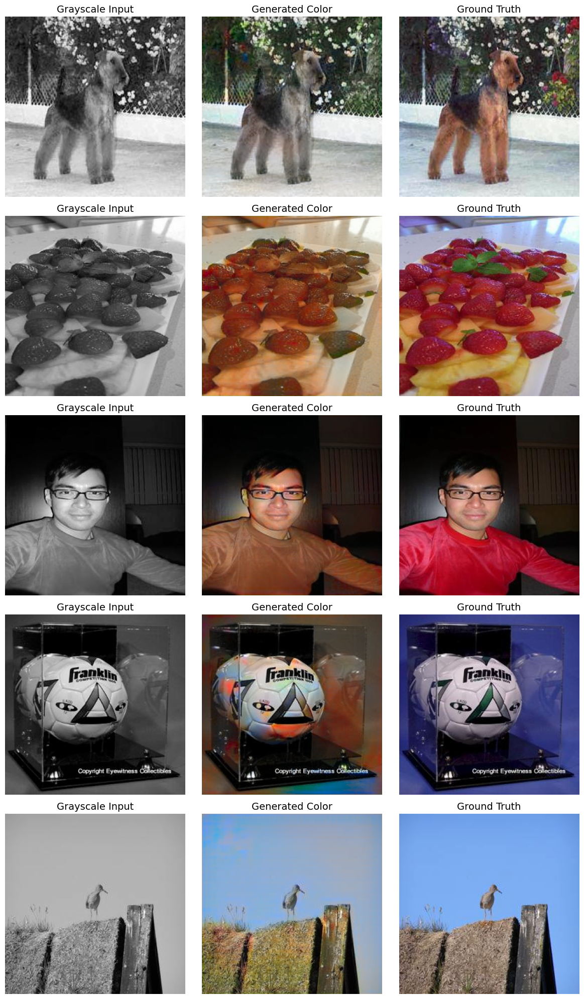

100%|██████████| 125/125 [00:47<00:00,  2.63it/s]


Final V1.5 Test Results:
Average SSIM: 0.9124
Average PSNR: 23.1658


(np.float32(0.9124472), np.float64(23.165828220607533))

In [ ]:
# ==========================================
# 5. EXECUTION & EVALUATION
# ==========================================
generator = AttentionUNet(in_ch=1, out_ch=2)
discriminator = PatchGANDiscriminator(in_ch=3)

generator.Up5.apply(init_weights)
generator.Att5.apply(init_weights)
generator.Up_conv5.apply(init_weights)
generator.Up4.apply(init_weights)
generator.Att4.apply(init_weights)
generator.Up_conv4.apply(init_weights)
generator.Up3.apply(init_weights)
generator.Att3.apply(init_weights)
generator.Up_conv3.apply(init_weights)
generator.Up2.apply(init_weights)
generator.Att2.apply(init_weights)
generator.Up_conv2.apply(init_weights)
generator.Up1.apply(init_weights)
generator.Up_conv1.apply(init_weights)
generator.Conv_1x1.apply(init_weights)

print("\n--- Starting V1.5 Training Phase ---")
train(generator, discriminator, train_loader, epochs=25)

def evaluate_model(generator, test_loader, num_visualize=5):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    generator = generator.to(device)
    generator.eval()

    total_ssim = 0.0
    total_psnr = 0.0
    num_batches = 0
    visualized = False

    print("Starting evaluation on test set...")
    with torch.no_grad():
        for L, ab_real in tqdm(test_loader):
            L = L.to(device)
            ab_fake = generator(L)

            rgb_fake = lab_to_rgb_tensor(L, ab_fake)
            rgb_real = lab_to_rgb_tensor(L.cpu(), ab_real)

            if not visualized:
                n_plot = min(num_visualize, L.shape[0])
                fig, axes = plt.subplots(n_plot, 3, figsize=(12, 4 * n_plot))
                if n_plot == 1: axes = [axes]

                for i in range(n_plot):
                    gray_img = (L[i, 0].cpu().numpy() + 1.0) / 2.0
                    axes[i][0].imshow(gray_img, cmap='gray')
                    axes[i][0].set_title("Grayscale Input", fontsize=14)
                    axes[i][0].axis('off')

                    axes[i][1].imshow(rgb_fake[i])
                    axes[i][1].set_title("Generated Color", fontsize=14)
                    axes[i][1].axis('off')

                    axes[i][2].imshow(rgb_real[i])
                    axes[i][2].set_title("Ground Truth", fontsize=14)
                    axes[i][2].axis('off')

                plt.tight_layout()
                plt.show()
                visualized = True

            batch_size = rgb_real.shape[0]
            for i in range(batch_size):
                current_ssim = ssim(rgb_real[i], rgb_fake[i], channel_axis=-1, data_range=1.0)
                current_psnr = psnr(rgb_real[i], rgb_fake[i], data_range=1.0)

                total_ssim += current_ssim
                total_psnr += current_psnr

            num_batches += batch_size

    avg_ssim = total_ssim / num_batches
    avg_psnr = total_psnr / num_batches

    print(f"\nFinal V1.5 Test Results:")
    print(f"Average SSIM: {avg_ssim:.4f}")
    print(f"Average PSNR: {avg_psnr:.4f}")

    return avg_ssim, avg_psnr

evaluate_model(generator, test_loader, num_visualize=5)